# Case Study 2: The G10 FX Carry Trade
DS 5005

**Return convention.** All carry P&L is in **daily percentage points**: $100\times$ the daily log spot return plus the interest-rate differential **compounded over actual calendar days** between observations. Annualization is mean $\times 252$ and volatility $\times\sqrt{252}$ throughout.

**Numeraire.** USD. Every spot series is expressed as **USD per unit of foreign currency**, so a rising series means the foreign currency strengthened, and a *long* position in a currency earns its own short rate and pays the USD short rate.

## Section 0 — Before You Start
The lecture pipeline (`lectures/fetch_data.py`, Modules 3–6) was built for one pair, AUD/JPY. This notebook rebuilds it for all ten G10 currencies (USD, EUR, JPY, GBP, CHF, CAD, AUD, NZD, SEK, NOK), checks whether the single-pair findings hold across the basket (Sections 2–3), builds and stress-tests a cross-sectional long/short carry basket (Sections 4–5), and adds an optional trend overlay (Section 6).

# Section 1 — Data Pipeline: Building the G10 Universe

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

RNG_SEED = 5005
np.random.seed(RNG_SEED)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

CURRENCIES = ["USD", "EUR", "JPY", "GBP", "CHF", "CAD", "AUD", "NZD", "SEK", "NOK"]
NON_USD = [c for c in CURRENCIES if c != "USD"]

## 1.1 — Short-Term Interest Rates

The lecture used FRED's OECD `IRSTCI01` family ("Immediate Rates: Call Money/Interbank Rate") for AUD and JPY. In each candidate `IRSTCI01{CC}M156N` series on FRED, looking at when it was last updated. Three have **stopped updating**:

| Currency | `IRSTCI01` status | Series used instead |
|---|---|---|
| CHF | last obs 2024-03 | `IR3TIB01CHM156N` (3-month interbank) |
| NZD | last obs 2024-12 | `IR3TIB01NZM156N` (3-month interbank) |
| SEK | last obs 2020-10 | `IR3TIB01SEM156N` (3-month interbank) |

USD, EUR (Euro-area aggregate), JPY, GBP, CAD, AUD and NOK all have a current monthly `IRSTCI01` series, which I use. Canada's monthly call-money series exists, so the `IR3TIB01` fallback the prompt mentions for CAD wasn't needed.

Two caveats, which the table printed below shows:
* **EUR is published with a longer lag** than the others, therefore I forward-fill it, so for the last few months of the sample the EUR rate is held at its last published value.
* **Timing.** Each FRED observation is a *monthly average* dated the first of the month, so the June value isn't fully known until the end of June. 

In [2]:
FRED_SERIES = {
    "USD": "IRSTCI01USM156N",
    "EUR": "IRSTCI01EZM156N",   # Euro-area aggregate
    "JPY": "IRSTCI01JPM156N",
    "GBP": "IRSTCI01GBM156N",
    "CHF": "IR3TIB01CHM156N",   # substitution: IRSTCI01CHM156N stale since 2024-03
    "CAD": "IRSTCI01CAM156N",
    "AUD": "IRSTCI01AUM156N",
    "NZD": "IR3TIB01NZM156N",   # substitution: IRSTCI01NZM156N stale since 2024-12
    "SEK": "IR3TIB01SEM156N",   # substitution: IRSTCI01SEM156N stale since 2020-10
    "NOK": "IRSTCI01NOM156N",
}
RATES_MAX_AGE_DAYS = 7

def get_g10_rates(force_refresh=False):
    """Disk-cached monthly short rates (% per year) for all 10 currencies.

    FRED publishes these monthly with a 1-5 month lag, so "is the newest
    observation recent?" can't be the test -- it would always fail and we'd
    re-download on every run. Instead, re-check FRED when the cache file is
    more than RATES_MAX_AGE_DAYS old.
    """
    path = DATA_DIR / "g10_rates.csv"
    if path.exists() and not force_refresh:
        age_days = (time.time() - path.stat().st_mtime) / 86400
        if age_days < RATES_MAX_AGE_DAYS:
            return pd.read_csv(path, index_col=0, parse_dates=True)

    frames = []
    for ccy, series_id in FRED_SERIES.items():
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
        s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
        s.columns = [ccy]
        frames.append(s)
    rates = pd.concat(frames, axis=1, sort=True)
    rates.index.name = "date"
    rates.to_csv(path)
    return rates

rates_raw = get_g10_rates()
rates = rates_raw.ffill()   # explicit: carry the last published rate forward
print(f"Rates: {rates_raw.index.min().date()} to {rates_raw.index.max().date()}")
pd.DataFrame({
    "series": pd.Series(FRED_SERIES),
    "first obs": rates_raw.apply(lambda s: s.dropna().index.min().date()),
    "last obs": rates_raw.apply(lambda s: s.dropna().index.max().date()),
    "latest value (%)": rates_raw.apply(lambda s: s.dropna().iloc[-1]).round(2),
})

Rates: 1954-07-01 to 2026-08-01


,series,first obs,last obs,latest value (%)
USD,IRSTCI01USM156N,1954-07-01,2026-08-01,3.63
EUR,IRSTCI01EZM156N,1994-01-01,2026-01-01,1.93
JPY,IRSTCI01JPM156N,1985-07-01,2026-08-01,0.98
GBP,IRSTCI01GBM156N,1978-01-01,2026-08-01,3.73
CHF,IR3TIB01CHM156N,1999-07-01,2026-08-01,-0.04
CAD,IRSTCI01CAM156N,1975-01-01,2026-08-01,2.25
AUD,IRSTCI01AUM156N,1990-08-01,2026-08-01,4.35
NZD,IR3TIB01NZM156N,1973-12-01,2026-08-01,2.98
SEK,IR3TIB01SEM156N,1982-01-01,2026-08-01,1.97
NOK,IRSTCI01NOM156N,1982-01-01,2026-08-01,4.25


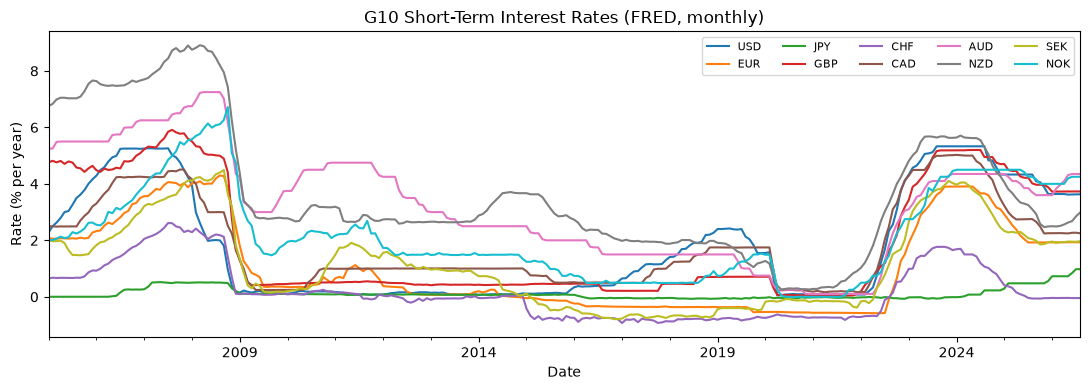

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
rates.loc["2005":].plot(ax=ax)
ax.set_title("G10 Short-Term Interest Rates (FRED, monthly)")
ax.set_ylabel("Rate (% per year)")
ax.set_xlabel("Date")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

## 1.2 — Spot FX Rates

Extending `fetch_data.py`'s Yahoo pull to all nine currencies. The quote direction differs by ticker:

* `EURUSD=X`, `GBPUSD=X`, `AUDUSD=X`, `NZDUSD=X` quote **USD per foreign unit** already.
* `USDJPY=X`, `USDCHF=X`, `USDCAD=X`, `USDSEK=X`, `USDNOK=X` quote **foreign units per USD**, so I invert them (`1/price`).

After this step, every column is USD per unit of foreign currency. 

In [4]:
FX_TICKERS_DIRECT   = {"EUR": "EURUSD=X", "GBP": "GBPUSD=X", "AUD": "AUDUSD=X", "NZD": "NZDUSD=X"}
FX_TICKERS_INVERTED = {"JPY": "USDJPY=X", "CHF": "USDCHF=X", "CAD": "USDCAD=X",
                       "SEK": "USDSEK=X", "NOK": "USDNOK=X"}
FX_START = "2005-01-01"

def _most_recent_expected_trading_day(as_of=None):
    """Yesterday, rolled back to Friday if it falls on a weekend."""
    d = (as_of or datetime.utcnow()) - timedelta(days=1)
    while d.weekday() >= 5:
        d -= timedelta(days=1)
    return d.date()

def get_g10_fx(force_refresh=False):
    """Disk-cached daily spot FX, USD per unit of foreign currency."""
    path = DATA_DIR / "g10_fx.csv"
    if path.exists() and not force_refresh:
        cached = pd.read_csv(path, index_col=0, parse_dates=True)
        if cached.index.max().date() >= _most_recent_expected_trading_day():
            return cached

    tickers = list(FX_TICKERS_DIRECT.values()) + list(FX_TICKERS_INVERTED.values())
    raw = yf.download(tickers, start=FX_START, auto_adjust=True, progress=False)["Close"]

    fx = pd.DataFrame(index=raw.index)
    for ccy, t in FX_TICKERS_DIRECT.items():
        fx[ccy] = raw[t]
    for ccy, t in FX_TICKERS_INVERTED.items():
        fx[ccy] = 1.0 / raw[t]
    fx = fx[NON_USD]
    fx.index.name = "date"
    fx.to_csv(path)
    return fx

fx_raw = get_g10_fx()
pd.DataFrame({
    "first obs": fx_raw.apply(lambda s: s.dropna().index.min().date()),
    "last obs": fx_raw.apply(lambda s: s.dropna().index.max().date()),
    "latest (USD per unit)": fx_raw.apply(lambda s: s.dropna().iloc[-1]).round(4),
})

,first obs,last obs,latest (USD per unit)
EUR,2005-01-03,2026-10-02,1.1257
JPY,2005-01-03,2026-10-03,0.0063
GBP,2005-01-03,2026-10-02,1.3240
CHF,2005-01-03,2026-10-02,1.2070
CAD,2005-01-03,2026-10-04,0.7019
AUD,2006-05-16,2026-10-03,0.6957
NZD,2005-01-03,2026-10-03,0.5623
SEK,2005-01-03,2026-10-04,0.0996
NOK,2005-01-03,2026-10-04,0.1040


**AUD** only starts on Yahoo in **May 2006**, so the common-date starts there.

**Data-quality scan.** Listing every daily move above 5% shows two kinds of event in the raw Yahoo data:

* **Real shocks, must stay in**, since the tail risk is what Section 5 is about: the SNB abandoning the EUR/CHF floor (CHF +17.6%, 2015-01-16 in Yahoo's dating), the SNB *introducing* the floor (CHF −9.2%, 2011-09-07), Brexit (GBP −7.9%), and AUD/NZD's large swings in October 2008. These moves don't reverse the next day.
* **Bad ticks, must come out:** single-day spikes that snap back the next day. EUR/USD shows the *same* value 1.5571 on 2008-01-08 and on 2008-02-08, and prints 1.49 on 2008-12-08 between 1.27 and 1.29. That would be a +16% day that never happened. 

The rule below targets the shape instead. Day $t$ is a bad tick if $|r_t| > 4\%$ **and** the next day moves at least 3% the other way, and the two moves roughly cancel ($|r_t + r_{t+1}| < 0.25\max(|r_t|,|r_{t+1}|)$). Flagged levels are nulled and interpolated. Every flagged date is printed. 

In [5]:
def clean_fx_glitches(fx, jump=0.04, reversal=0.03, max_residual=0.25):
    """Null one-day spikes: |r_t| > jump, followed by an opposite move
    |r_{t+1}| > reversal that roughly cancels it (net move < 25% of the larger leg). One-way jumps are left alone."""
    fx = fx.copy()
    for ccy in fx.columns:
        s = fx[ccy].copy()
        r = np.log(s.dropna()).diff()
        r_next = r.shift(-1)
        spike = ((r.abs() > jump) & (r_next.abs() > reversal)
                 & (np.sign(r) != np.sign(r_next))
                 & ((r + r_next).abs() < max_residual * np.maximum(r.abs(), r_next.abs())))
        for d in r.index[spike]:
            print(f"  {ccy} {d.date()}: {100*r[d]:+.1f}% then {100*r_next[d]:+.1f}% -> bad tick, nulled")
        s.loc[r.index[spike]] = np.nan
        fx[ccy] = s.interpolate(limit_area="inside")
    return fx

print("FX glitch scan:")
fx = clean_fx_glitches(fx_raw)

r_clean = 100 * np.log(fx).diff()
print("\nLargest remaining one-day moves (%), all should be real events:")
print(r_clean.stack().abs().sort_values(ascending=False).head(6).round(1).to_string())

FX glitch scan:
  EUR 2008-01-08: +5.9% then -6.0% -> bad tick, nulled
  EUR 2008-02-08: +7.3% then -7.1% -> bad tick, nulled
  EUR 2008-09-08: +5.3% then -6.2% -> bad tick, nulled
  EUR 2008-10-08: +9.6% then -9.5% -> bad tick, nulled
  EUR 2008-12-08: +16.0% then -14.3% -> bad tick, nulled
  JPY 2008-04-08: -5.5% then +6.1% -> bad tick, nulled
  JPY 2008-10-08: -8.2% then +10.1% -> bad tick, nulled
  JPY 2008-12-08: -16.3% then +16.8% -> bad tick, nulled
  CHF 2009-02-06: +7.9% then -7.5% -> bad tick, nulled
  AUD 2008-11-20: -4.5% then +3.5% -> bad tick, nulled
  NOK 2008-10-22: -4.7% then +5.6% -> bad tick, nulled
  NOK 2019-01-01: +4.1% then -3.4% -> bad tick, nulled
  NOK 2020-01-01: +5.3% then -4.8% -> bad tick, nulled
  NOK 2020-03-20: +33.2% then -41.9% -> bad tick, nulled
  NOK 2021-01-01: +10.9% then -11.1% -> bad tick, nulled
  NOK 2021-12-27: +9.8% then -9.9% -> bad tick, nulled

Largest remaining one-day moves (%), all should be real events:
date           
2015-01-16  CH

## 1.3 — The Cache

Both loaders read from `data/*.csv` and only go to the network when the cache is out of date:

* **FX (daily):** re-download if the cached file doesn't reach the most recent expected trading day. Around exchange holidays this can trigger one unnecessary refresh, but this is harmless.
* **Rates (monthly):** FRED publishes these with a lag of one to five months, so a "does the cache reach last month?" test would fail on every run and re-download each time. Instead I re-check FRED when the cache file is more than 7 days old.

Both loaders take `force_refresh=True` to override the cache. **As-of date:** see the printout below. 

In [6]:
print("Rates cache written:", datetime.fromtimestamp((DATA_DIR / "g10_rates.csv").stat().st_mtime).date())
print("FX data through:    ", fx.index.max().date())

Rates cache written: 2026-09-28
FX data through:     2026-10-04


## 1.4 — Constructing Per-Currency Carry P&L

**NaN handling:** each currency's P&L starts on its own first valid date. I then keep only dates where **all nine** have a value, which gives one aligned panel starting on AUD's first date.

In [7]:
def accrued_pct(annual_rate_pct, n_days, day_count=365):
    return ((1 + annual_rate_pct / 100) ** (n_days / day_count) - 1) * 100

def get_carry_pnl(rates, fx):
    daily_idx = fx.index
    r = rates.reindex(rates.index.union(daily_idx)).ffill().reindex(daily_idx)
    carry = {}
    for ccy in NON_USD:
        spot = fx[ccy].dropna()
        log_ret = 100 * np.log(spot).diff()
        n_days = spot.index.to_series().diff().dt.days
        carry[ccy] = (log_ret
                      + accrued_pct(r.loc[spot.index, ccy], n_days)
                      - accrued_pct(r.loc[spot.index, "USD"], n_days))
    carry_all = pd.DataFrame(carry)
    return carry_all.dropna(how="any"), carry_all

carry, carry_unaligned = get_carry_pnl(rates, fx)
print(f"Carry P&L panel: {carry.shape[0]} days x {carry.shape[1]} currencies, "
      f"{carry.index.min().date()} to {carry.index.max().date()}")
print(f"Rows dropped by the all-nine inner join: {len(carry_unaligned) - len(carry)}")
carry.describe().T.round(4)

Carry P&L panel: 5303 days x 9 currencies, 2006-05-17 to 2026-10-02
Rows dropped by the all-nine inner join: 359


,count,mean,std,min,25%,50%,75%,max
EUR,5303.0,-0.0054,0.5613,-2.8177,-0.3101,-0.0081,0.2970,3.4026
JPY,5303.0,-0.0130,0.6263,-5.2336,-0.3392,-0.0289,0.3052,5.1803
GBP,5303.0,-0.0065,0.5838,-7.9078,-0.3073,-0.0028,0.3090,3.4940
CHF,5303.0,0.0010,0.6354,-9.2359,-0.3151,-0.0221,0.3123,17.6094
CAD,5303.0,-0.0046,0.5326,-3.5943,-0.2797,-0.0077,0.2692,3.6988
AUD,5303.0,0.0031,0.7699,-7.7466,-0.3850,0.0241,0.4127,9.0420
NZD,5303.0,0.0041,0.7677,-6.7786,-0.4216,0.0113,0.4515,5.3188
SEK,5303.0,-0.0084,0.7489,-4.5335,-0.4122,-0.0051,0.4045,5.0023
NOK,5303.0,-0.0069,0.7745,-4.6422,-0.4278,0.0078,0.4325,4.0934


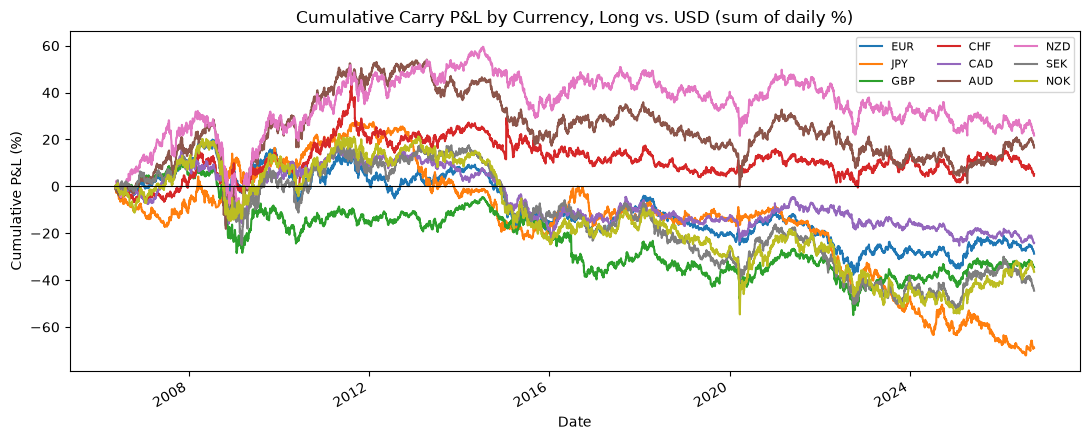

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
carry.cumsum().plot(ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Cumulative Carry P&L by Currency, Long vs. USD (sum of daily %)")
ax.set_ylabel("Cumulative P&L (%)")
ax.set_xlabel("Date")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

# Section 2 — Revisiting Modules 3–4: Is the Single-Pair Story Robust?

## 2.1 — Random Walk / Stationarity Check, Basket-Wide

USD is the numeraire, so the "ten spot series" are the nine non-USD currencies quoted in USD. For each one:

* **ADF test** on log-price and on log-return. $H_0$: unit root. A random walk should *fail to reject* in levels and *reject* in returns.
* **Ljung-Box test** (10 lags) on log-returns. $H_0$: no autocorrelation. A random walk has uncorrelated increments, so we expect to *fail to reject*. With about 5,000 observations, tiny autocorrelations can still come out "significant", so compare the size of the SACF bars, not just the $p$-value.
* **SACF grids** of log-price and log-return.

In [9]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

rw_rows = []
for ccy in NON_USD:
    log_p = np.log(fx[ccy].dropna())
    log_r = log_p.diff().dropna()
    adf_p, adf_r = adfuller(log_p, autolag="AIC"), adfuller(log_r, autolag="AIC")
    lb = acorr_ljungbox(log_r, lags=[10])
    rw_rows.append({
        "ccy": ccy,
        "ADF stat (log price)": adf_p[0], "ADF p (log price)": adf_p[1],
        "ADF stat (log return)": adf_r[0], "ADF p (log return)": adf_r[1],
        "LB(10) p (log return)": lb["lb_pvalue"].iloc[0],
        "lag-1 autocorr (return)": log_r.autocorr(1),
    })
rw_df = pd.DataFrame(rw_rows).set_index("ccy").round(4)
rw_df

,ADF stat (log price),ADF p (log price),ADF stat (log return),ADF p (log return),LB(10) p (log return),lag-1 autocorr (return)
ccy,,,,,,
EUR,-2.0227,0.2767,-76.7073,0.0,0.4041,-0.0193
JPY,-0.5506,0.8818,-19.8544,0.0,0.0031,-0.0456
GBP,-1.8363,0.3626,-73.5545,0.0,0.2839,0.0225
CHF,-1.9483,0.3097,-75.1990,0.0,0.4979,0.0006
CAD,-1.1743,0.6846,-14.3287,0.0,0.0004,-0.0138
AUD,-1.7280,0.4167,-19.4234,0.0,0.0000,-0.0551
NZD,-2.2065,0.2039,-19.2128,0.0,0.0322,-0.0085
SEK,-1.4318,0.5670,-45.4976,0.0,0.0117,-0.0447
NOK,-1.2018,0.6728,-45.1572,0.0,0.2107,-0.0009


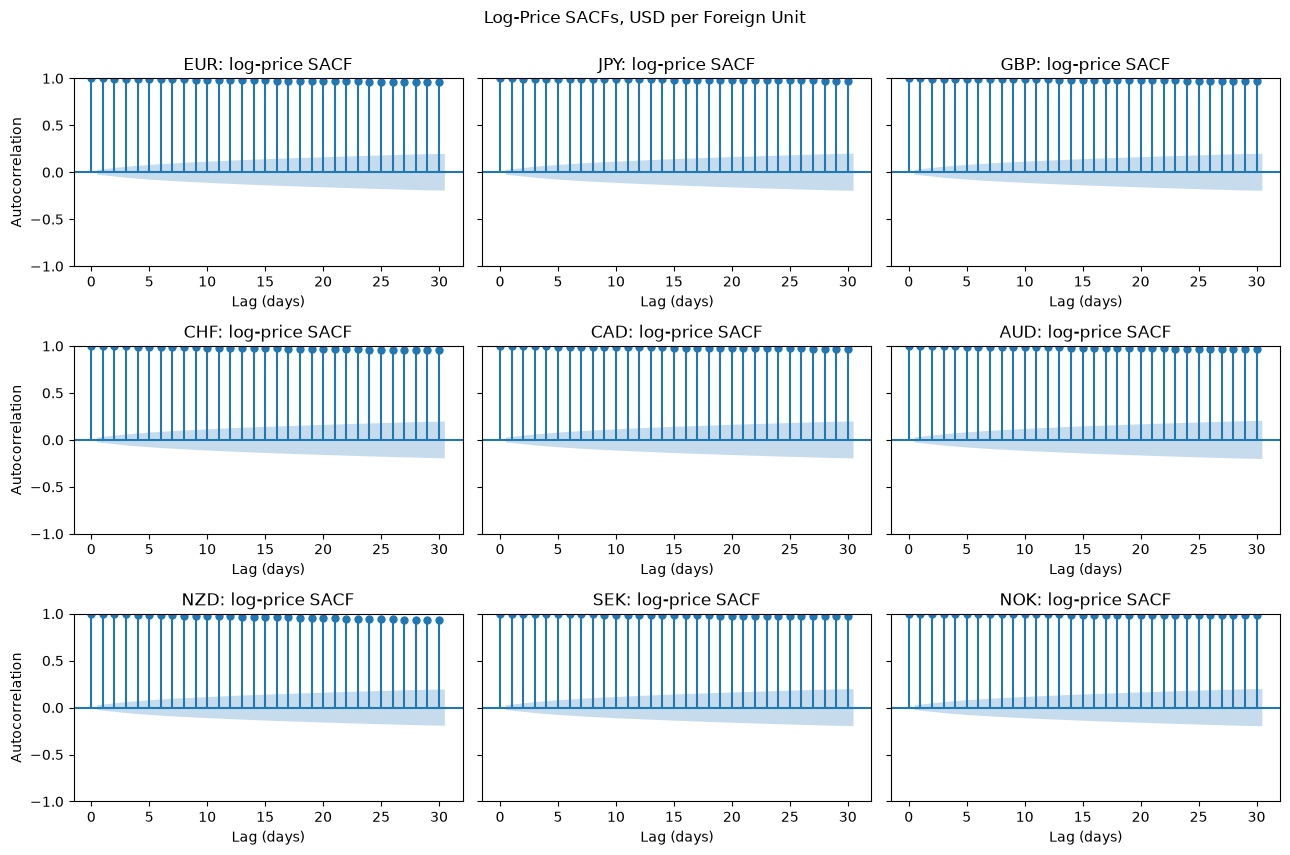

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharey=True)
for ax, ccy in zip(axes.flat, NON_USD):
    plot_acf(np.log(fx[ccy].dropna()), lags=30, ax=ax, title=f"{ccy}: log-price SACF")
    ax.set_xlabel("Lag (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("Autocorrelation")
fig.suptitle("Log-Price SACFs, USD per Foreign Unit", y=1.0)
plt.tight_layout()
plt.show()

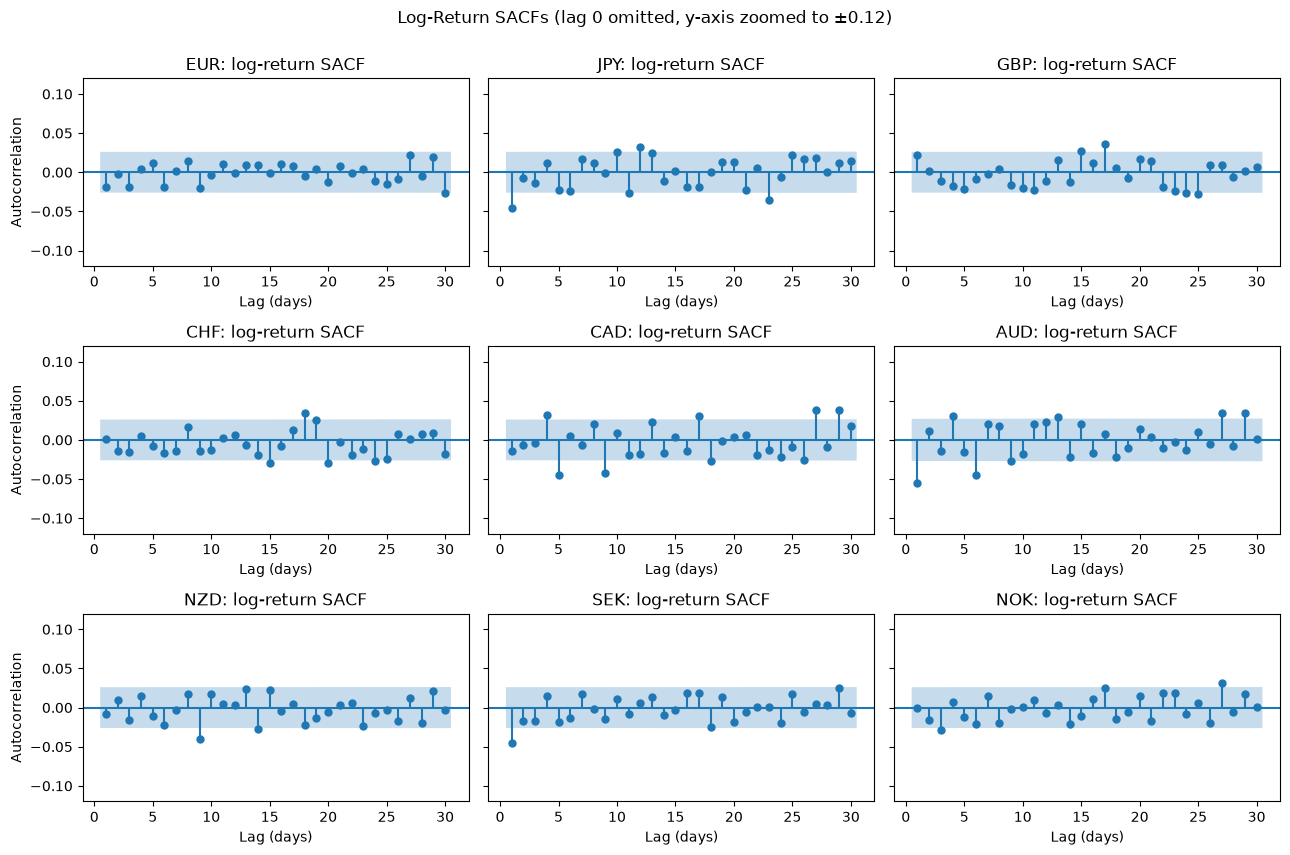

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharey=True)
for ax, ccy in zip(axes.flat, NON_USD):
    plot_acf(np.log(fx[ccy].dropna()).diff().dropna(), lags=30, zero=False, ax=ax,
             title=f"{ccy}: log-return SACF")
    ax.set_ylim(-0.12, 0.12)
    ax.set_xlabel("Lag (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("Autocorrelation")
fig.suptitle("Log-Return SACFs (lag 0 omitted, y-axis zoomed to ±0.12)", y=1.0)
plt.tight_layout()
plt.show()

**Interpretation (2.1).** 
Every currency's log-price behaves like a random walk, as these are not stationary datasets. However, the returns are stationary. These data have some events that peek out of significcance, but they are likely just due to sample size and not economically relevant. 

## 2.2 — Mean Carry Return: Basket-Wide Significance

Module 4's IID mean test, run for each currency: $H_0:\ \mu = 0$, with $t = \bar x / (s/\sqrt{n})$.

To answer the forward-premium question, the table also splits each currency's annualized carry into its two parts:
* **rate-diff income**: the accrued $i_k - i_{\text{USD}}$, averaged over the **same dates as the P&L** (not FRED's full history, which goes back to the 1950s for some series);
* **spot return**: the FX move.

UIP says the spot move should offset the rate differential, so that carry ≈ 0. The forward premium puzzle says it doesn't. I also add **AUD/JPY** for continuity with the lecture. Long AUD vs USD plus short JPY vs USD makes the USD legs cancel exactly, so AUD/JPY carry = `carry["AUD"] − carry["JPY"]`.

In [12]:
from scipy import stats

carry_x = carry.copy()
carry_x["AUD/JPY"] = carry["AUD"] - carry["JPY"]

# daily accrued rate-diff component on the carry dates (same construction as 1.4)
daily_rates = rates.reindex(rates.index.union(fx.index)).ffill().reindex(carry.index)
n_days = fx.index.to_series().diff().dt.days.reindex(carry.index)
income = pd.DataFrame({c: accrued_pct(daily_rates[c], n_days) - accrued_pct(daily_rates["USD"], n_days)
                       for c in NON_USD})
income["AUD/JPY"] = income["AUD"] - income["JPY"]

mean_rows = []
for col in carry_x.columns:
    s = carry_x[col]
    n, xbar, sd = len(s), s.mean(), s.std(ddof=1)
    se = sd / np.sqrt(n)
    t = xbar / se
    mean_rows.append({
        "ccy": col, "n": n,
        "mean (%/day)": xbar, "se": se, "t-stat": t,
        "p-value": 2 * stats.t.sf(abs(t), df=n - 1),
        "carry (%/yr)": 252 * xbar,
        "rate-diff income (%/yr)": 252 * income[col].mean(),
        "spot return (%/yr)": 252 * (xbar - income[col].mean()),
    })
mean_df = (pd.DataFrame(mean_rows).set_index("ccy")
           .sort_values("rate-diff income (%/yr)", ascending=False))
mean_df.round(4)

,n,mean (%/day),se,t-stat,p-value,carry (%/yr),rate-diff income (%/yr),spot return (%/yr)
ccy,,,,,,,,
AUD/JPY,5303,0.0161,0.0134,1.2018,0.2295,4.0594,2.8141,1.2453
NZD,5303,0.0041,0.0105,0.3878,0.6982,1.0303,1.5583,-0.5280
AUD,5303,0.0031,0.0106,0.2948,0.7682,0.7854,1.2690,-0.4837
NOK,5303,-0.0069,0.0106,-0.6474,0.5174,-1.7350,0.4347,-2.1698
GBP,5303,-0.0065,0.0080,-0.8107,0.4175,-1.6378,0.0468,-1.6846
CAD,5303,-0.0046,0.0073,-0.6252,0.5319,-1.1523,0.0378,-1.1901
SEK,5303,-0.0084,0.0103,-0.8165,0.4142,-2.1161,-0.6119,-1.5042
EUR,5303,-0.0054,0.0077,-0.7032,0.4820,-1.3658,-0.7370,-0.6288
CHF,5303,0.0010,0.0087,0.1132,0.9099,0.2488,-1.5425,1.7913


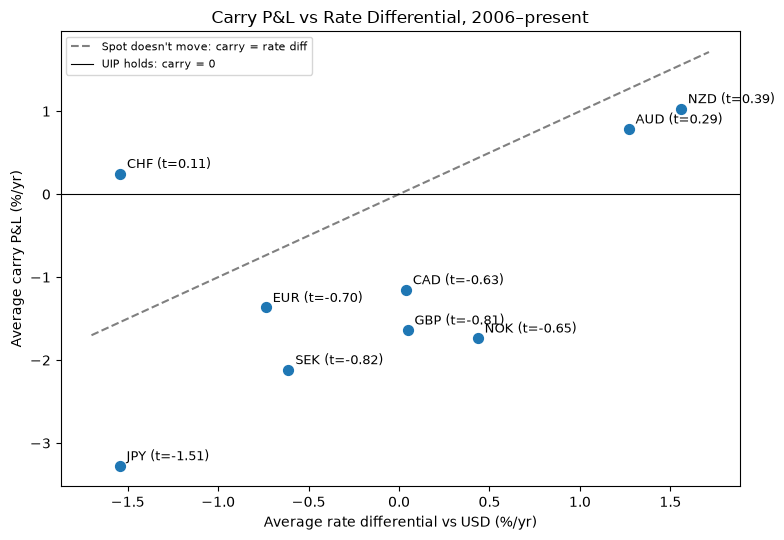

In [13]:
pts = mean_df.drop(index="AUD/JPY")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(pts["rate-diff income (%/yr)"], pts["carry (%/yr)"], s=50, zorder=3)
for ccy, row in pts.iterrows():
    ax.annotate(f"{ccy} (t={row['t-stat']:.2f})",
                (row["rate-diff income (%/yr)"], row["carry (%/yr)"]),
                xytext=(5, 4), textcoords="offset points", fontsize=9)
lim = np.array(ax.get_xlim())
ax.plot(lim, lim, ls="--", color="gray", label="Spot doesn't move: carry = rate diff")
ax.axhline(0, color="black", lw=0.8, label="UIP holds: carry = 0")
ax.set_xlabel("Average rate differential vs USD (%/yr)")
ax.set_ylabel("Average carry P&L (%/yr)")
ax.set_title("Carry P&L vs Rate Differential, 2006–present")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation (2.2).** 

None of the currencies have a significant positive or negative mean carry. In general, there is a relationship between the largest average rate differential and  the most robust positive carry P&L. There is one currency that does not follow this, CHF, but the others follow closely. 

## 2.3 — Bootstrap Robustness

I resample days with replacement (1,000 resamples) and recompute the mean carry for:

* **AUD/JPY, full sample (2006–)**, for continuity with the lecture;
* **AUD/JPY, lecture window (2010–)**, the period `lectures/data/carry_pnl.csv` covers. The question is whether the lecture's finding depends on its start date;
* **NZD**, the highest-yielding currency vs USD;
* **JPY**, the classic funding currency.


In [14]:
rng = np.random.default_rng(RNG_SEED)
N_BOOT = 1000
LECTURE_START = "2010-01-01"

boot_series = {
    "AUD/JPY (2006–)": carry_x["AUD/JPY"],
    "AUD/JPY (2010–, lecture window)": carry_x["AUD/JPY"].loc[LECTURE_START:],
    "NZD": carry_x["NZD"],
    "JPY": carry_x["JPY"],
}

boot_means = {}
for name, s in boot_series.items():
    v = s.to_numpy()
    idx = rng.integers(0, len(v), size=(N_BOOT, len(v)))
    boot_means[name] = v[idx].mean(axis=1)

boot_summary = pd.DataFrame({
    name: {
        "sample mean (%/day)": s.mean(),
        "IID se": s.std() / np.sqrt(len(s)),
        "bootstrap se": boot_means[name].std(ddof=1),
        "2.5%": np.percentile(boot_means[name], 2.5),
        "97.5%": np.percentile(boot_means[name], 97.5),
        "share of resamples <= 0": (boot_means[name] <= 0).mean(),
    }
    for name, s in boot_series.items()
}).T
boot_summary.round(4)

,sample mean (%/day),IID se,bootstrap se,2.5%,97.5%,share of resamples <= 0
AUD/JPY (2006–),0.0161,0.0134,0.0134,-0.0124,0.0421,0.126
"AUD/JPY (2010–, lecture window)",0.0156,0.0118,0.0119,-0.0074,0.0381,0.097
NZD,0.0041,0.0105,0.0103,-0.0164,0.0238,0.349
JPY,-0.0130,0.0086,0.0086,-0.0298,0.0033,0.937


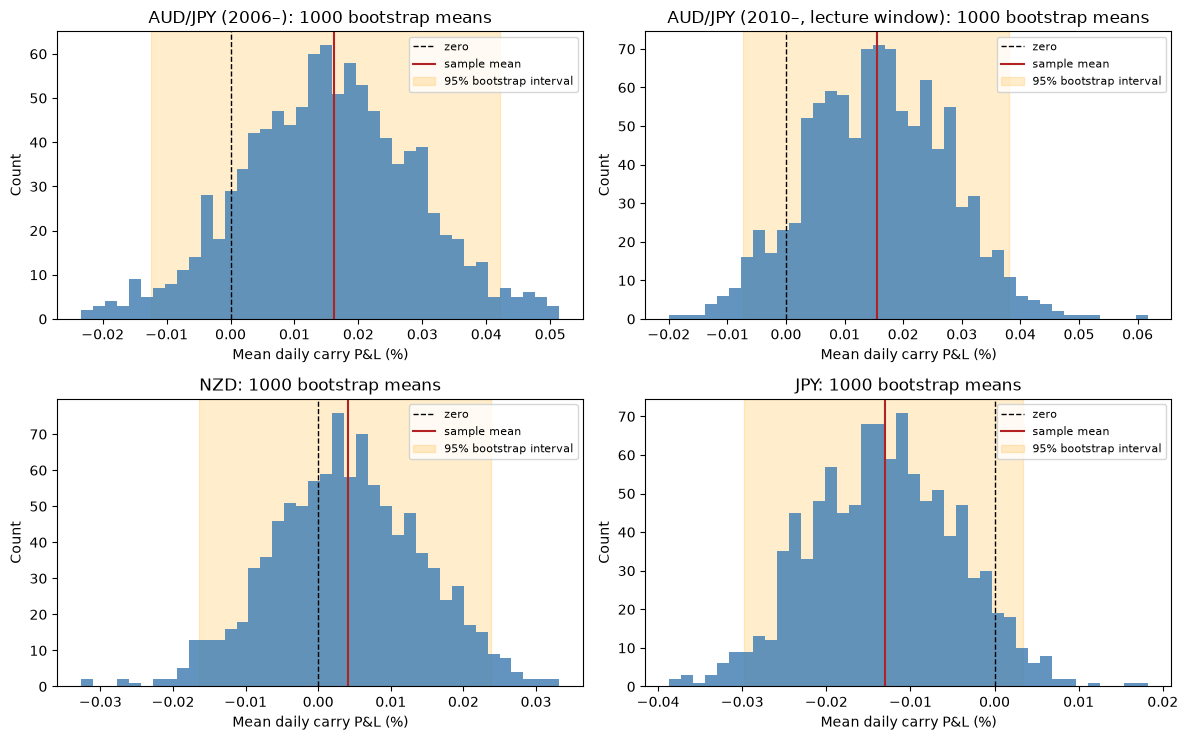

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (name, means) in zip(axes.flat, boot_means.items()):
    ax.hist(means, bins=40, color="steelblue", alpha=0.85)
    ax.axvline(0, color="black", ls="--", lw=1, label="zero")
    ax.axvline(boot_series[name].mean(), color="firebrick", lw=1.5, label="sample mean")
    lo, hi = np.percentile(means, [2.5, 97.5])
    ax.axvspan(lo, hi, color="orange", alpha=0.2, zorder=0, label="95% bootstrap interval")
    ax.set_title(f"{name}: {N_BOOT} bootstrap means")
    ax.set_xlabel("Mean daily carry P&L (%)")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation (2.3).**

The 95% interval for all of the currencies include zero, so there is not sufficient evidence to suggest the means are different than zero. The answer does not change (much) depending on a 2006 start compared to the 2010 start. This was surprising to me, because of the major financial crash. The data is nor robust, because the means include zero. 

# Section 3 — Revisiting Modules 5–6: Mean Predictability and Volatility per Currency

## 3.1 — ARMA Identification, Basket-Wide

As in Module 5: look at the ACF/PACF of each currency's carry P&L, then grid-search ARMA($p,q$) for $p, q \in \{0,\dots,3\}$ and pick the order by AIC and by BIC.

An information criterion can pick a nonzero order with $n \approx 5{,}300$ even when the structure is too small to trade. So the table also reports:
* **ΔBIC vs white noise**: how much better the BIC-best model scores than ARMA(0,0). Rough guide: < 2 is negligible, > 10 is strong.
* **In-sample $R^2$** of the BIC-best model: the share of daily carry variance it explains. This shows whether the predictability is economically meaningful.



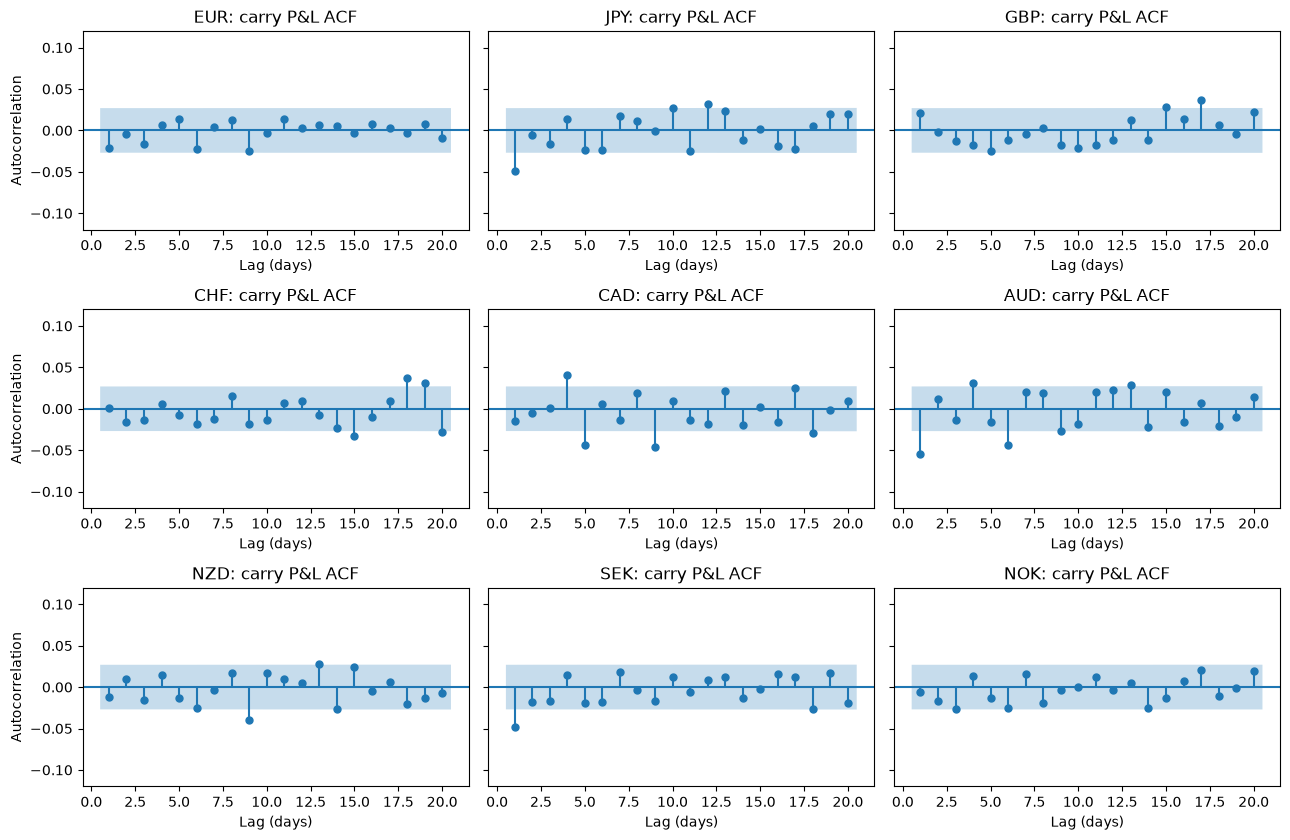

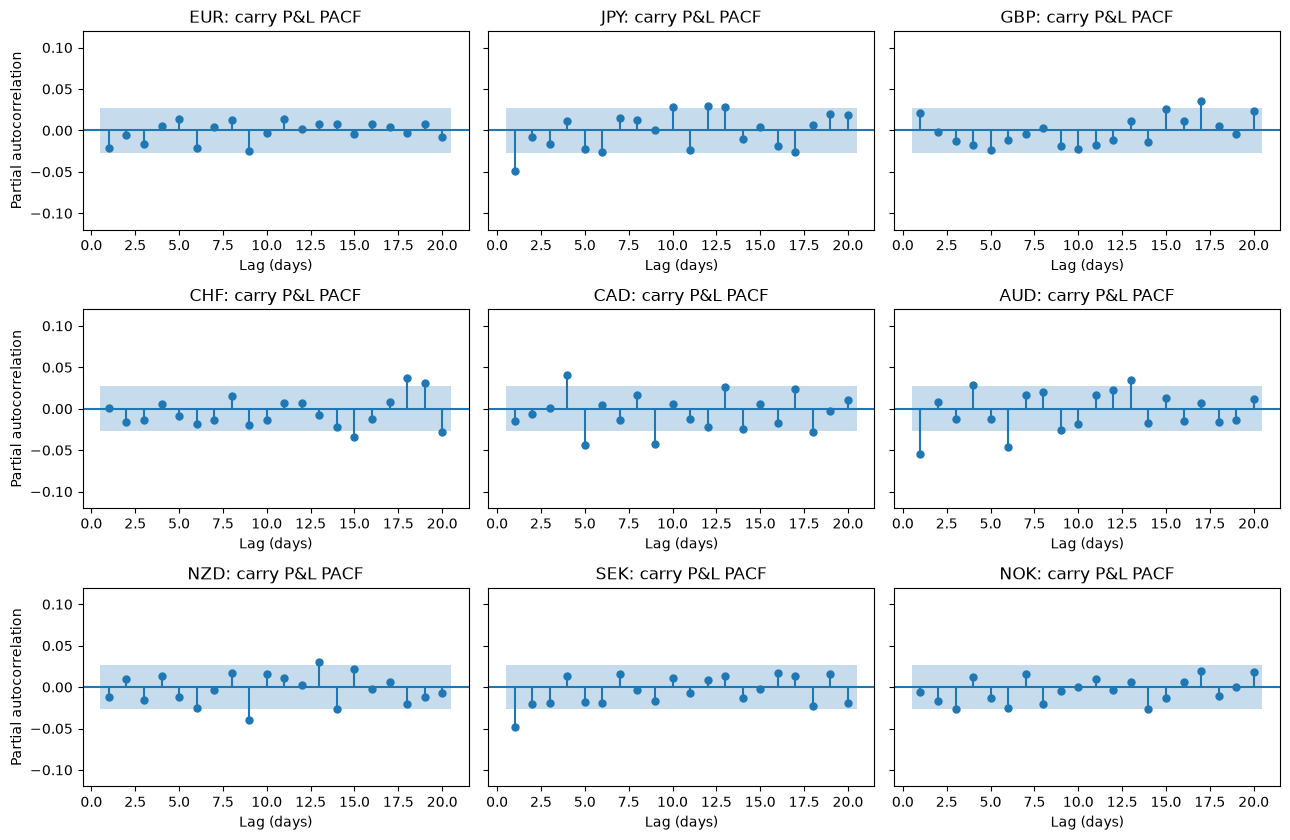

In [16]:
from statsmodels.graphics.tsaplots import plot_pacf

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharey=True)
for ax, ccy in zip(axes.flat, NON_USD):
    plot_acf(carry[ccy], lags=20, zero=False, ax=ax, title=f"{ccy}: carry P&L ACF")
    ax.set_ylim(-0.12, 0.12)
    ax.set_xlabel("Lag (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharey=True)
for ax, ccy in zip(axes.flat, NON_USD):
    plot_pacf(carry[ccy], lags=20, zero=False, method="ywm", ax=ax, title=f"{ccy}: carry P&L PACF")
    ax.set_ylim(-0.12, 0.12)
    ax.set_xlabel("Lag (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("Partial autocorrelation")
plt.tight_layout()
plt.show()

In [17]:
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

ORDERS = [(p, q) for p in range(4) for q in range(4)]

arma_rows = []
for ccy in NON_USD:
    y = carry[ccy].to_numpy()
    ic = {}
    for p, q in ORDERS:
        try:
            res = ARIMA(y, order=(p, 0, q), trend="c").fit()
            ic[(p, q)] = (res.aic, res.bic, res)
        except Exception as e:   # report, don't silently drop, a failed fit
            print(f"  {ccy} ARMA{(p, q)} failed: {e}")
    best_aic = min(ic, key=lambda k: ic[k][0])
    best_bic = min(ic, key=lambda k: ic[k][1])
    best = ic[best_bic][2]
    arma_rows.append({
        "ccy": ccy,
        "best (p,q) by AIC": best_aic,
        "best (p,q) by BIC": best_bic,
        "ΔBIC vs (0,0)": ic[(0, 0)][1] - ic[best_bic][1],
        "in-sample R² (BIC-best)": 1 - best.resid.var() / y.var(),
    })
    print(f"  {ccy}: AIC -> {best_aic}, BIC -> {best_bic}")
arma_df = pd.DataFrame(arma_rows).set_index("ccy")
arma_df.round(4)

c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\en

  EUR: AIC -> (3, 3), BIC -> (0, 0)


c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\en

  JPY: AIC -> (2, 3), BIC -> (0, 1)


c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\en

...

  SEK: AIC -> (2, 3), BIC -> (0, 1)


c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\waltt\miniconda3\en

  NOK: AIC -> (2, 3), BIC -> (0, 0)


c:\Users\waltt\miniconda3\envs\quant-ts\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,"best (p,q) by AIC","best (p,q) by BIC","ΔBIC vs (0,0)",in-sample R² (BIC-best)
ccy,,,,
EUR,"(3, 3)","(0, 0)",0.0000,0.0000
JPY,"(2, 3)","(0, 1)",4.4435,0.0025
GBP,"(2, 3)","(0, 0)",0.0000,0.0000
CHF,"(1, 1)","(0, 0)",0.0000,0.0000
CAD,"(2, 3)","(0, 0)",0.0000,0.0000
AUD,"(3, 3)","(1, 0)",7.5613,0.0030
NZD,"(2, 3)","(0, 0)",0.0000,0.0000
SEK,"(2, 3)","(0, 1)",4.0735,0.0024
NOK,"(2, 3)","(0, 0)",0.0000,0.0000


**Interpretation (3.1).**

Most currencies pick (0,0) for the BIC models selection, and the ones where it does, the BIC is large. The lecture's "no meaningful mean predictability" finding holds basket-wide. 

## 3.2 — GARCH Fitting, Basket-Wide

For each currency: GARCH(1,1) with a constant mean, fit with Normal and with Student-$t$ innovations (Module 6). The table reports:
* $\hat\alpha_1$, $\hat\beta_1$, persistence $\hat\alpha_1+\hat\beta_1$, and the **half-life** of a volatility shock, $\ln 0.5 / \ln(\hat\alpha_1+\hat\beta_1)$ trading days;
* which innovation distribution wins by **AIC** and by **BIC**;
* **Ljung-Box (10 lags)** on raw squared carry, and on absolute carry, *before* fitting. Rejecting means there is volatility clustering to model. The $|{\rm carry}|$ version matters because a single huge day (CHF, 2015-01-16) can swamp the autocorrelation of the squared series and hide clustering that is there;
* **Ljung-Box** on the winning model's standardized residuals $\hat z_t$ and on $\hat z_t^2$, *after* fitting. Failing to reject on $\hat z_t^2$ means GARCH has absorbed the clustering.



In [18]:
from arch import arch_model

def lb_p(x, lags=10):
    return acorr_ljungbox(x, lags=[lags])["lb_pvalue"].iloc[0]

garch_fits, garch_rows = {}, []
for ccy in NON_USD:
    y = carry[ccy]
    fits = {d: arch_model(y, mean="Constant", vol="GARCH", p=1, q=1, dist=d).fit(disp="off")
            for d in ("normal", "t")}
    win_aic = min(fits, key=lambda d: fits[d].aic)
    win_bic = min(fits, key=lambda d: fits[d].bic)
    best = fits[win_bic]
    z = best.std_resid.dropna()
    a, b = best.params["alpha[1]"], best.params["beta[1]"]
    garch_fits[ccy] = {"normal": fits["normal"], "t": fits["t"], "best": best, "dist": win_bic}
    garch_rows.append({
        "ccy": ccy,
        "alpha1": a, "beta1": b, "persistence": a + b,
        "half-life (days)": np.log(0.5) / np.log(a + b),
        "nu (t fit)": fits["t"].params["nu"],
        "AIC winner": win_aic, "BIC winner": win_bic,
        "LB p: carry² (pre-fit)": lb_p(y ** 2),
        "LB p: |carry| (pre-fit)": lb_p(y.abs()),
        "LB p: z (post-fit)": lb_p(z),
        "LB p: z² (post-fit)": lb_p(z ** 2),
    })
garch_df = pd.DataFrame(garch_rows).set_index("ccy")
garch_df.round(4)

,alpha1,beta1,persistence,half-life (days),nu (t fit),AIC winner,BIC winner,LB p: carry² (pre-fit),LB p: |carry| (pre-fit),LB p: z (post-fit),LB p: z² (post-fit)
ccy,,,,,,,,,,,
EUR,0.0389,0.9588,0.9977,304.1598,7.7732,t,t,0.0000,0.0,0.1706,0.6186
JPY,0.0831,0.9097,0.9928,95.4629,5.0880,t,t,0.0000,0.0,0.2458,0.4086
GBP,0.0414,0.9512,0.9926,92.9785,6.9272,t,t,0.0000,0.0,0.9242,0.0846
CHF,0.0362,0.9539,0.9902,70.1506,6.2973,t,t,0.6995,0.0,0.7550,1.0000
CAD,0.0478,0.9485,0.9963,188.6131,7.6552,t,t,0.0000,0.0,0.3174,0.0031
AUD,0.0525,0.9391,0.9916,82.5307,9.4683,t,t,0.0000,0.0,0.1848,0.3245
NZD,0.0449,0.9466,0.9915,81.0296,11.5666,t,t,0.0000,0.0,0.2766,0.3510
SEK,0.0388,0.9553,0.9941,117.2896,9.5204,t,t,0.0000,0.0,0.0990,0.2411
NOK,0.0403,0.9557,0.9960,174.4017,9.1282,t,t,0.0000,0.0,0.5747,0.0329


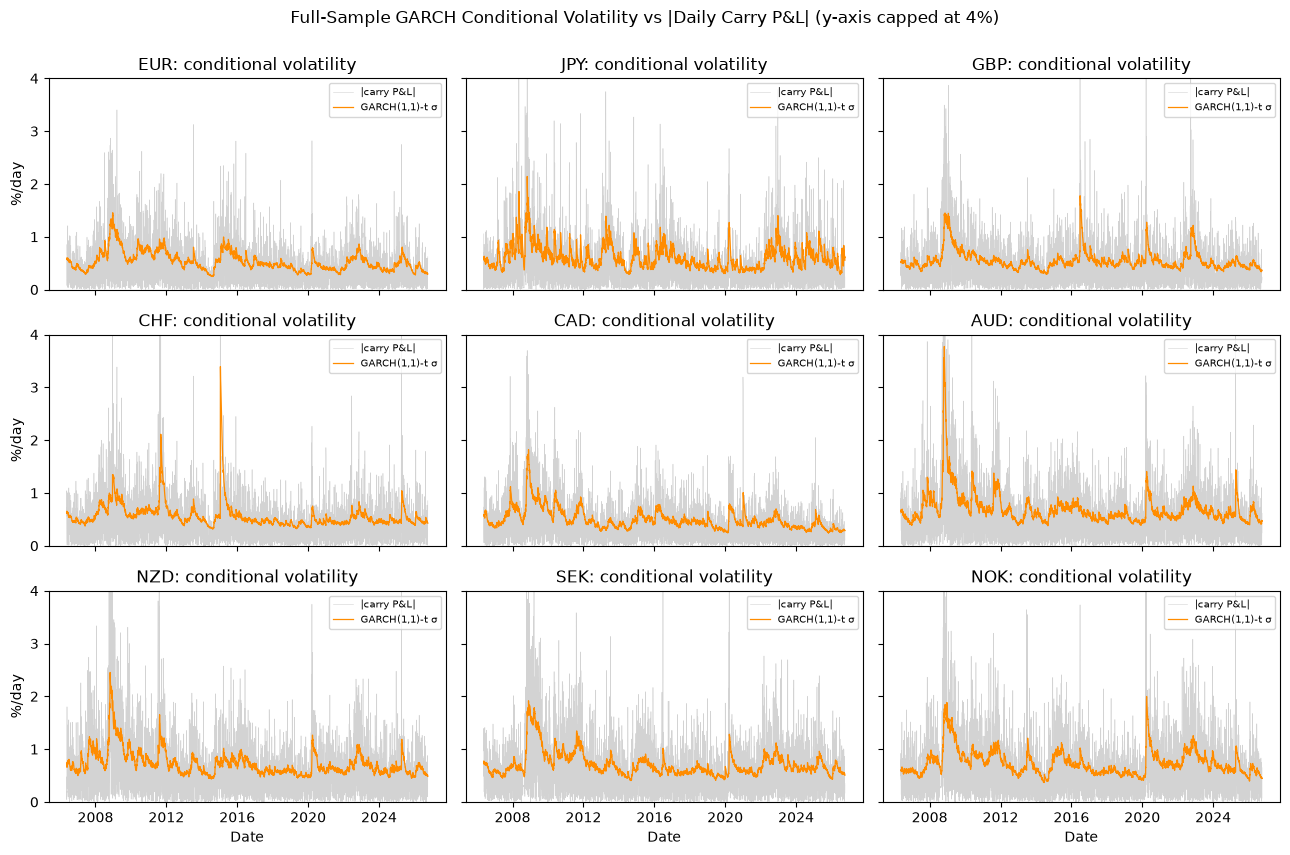

In [19]:
cond_vol_full = pd.DataFrame({c: garch_fits[c]["best"].conditional_volatility for c in NON_USD})

fig, axes = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, ccy in zip(axes.flat, NON_USD):
    ax.plot(carry.index, carry[ccy].abs(), lw=0.4, color="lightgray", label="|carry P&L|")
    ax.plot(cond_vol_full.index, cond_vol_full[ccy], lw=0.9, color="darkorange",
            label=f"GARCH(1,1)-{garch_fits[ccy]['dist']} σ")
    ax.set_title(f"{ccy}: conditional volatility")
    ax.set_ylim(0, 4)
    ax.legend(fontsize=7, loc="upper right")
for ax in axes[:, 0]:
    ax.set_ylabel("%/day")
for ax in axes[-1, :]:
    ax.set_xlabel("Date")
fig.suptitle("Full-Sample GARCH Conditional Volatility vs |Daily Carry P&L| (y-axis capped at 4%)", y=1.0)
plt.tight_layout()
plt.show()

**Interpretation (3.2).** 

Every currency shows volatility clustering. There are spikes along major financial crashes (2008, 2020), which would be expected. There are changes on the half life, where the Euro has the highest, and the CHF has the lowest. Suggesting the euro reacts the least and takes the longest to fade, and CHF has the inverse effect. Student T wins for every scenario. 

## 3.3 — The Fama Regression, Basket-Wide

$$
\Delta s_{t+1} = \alpha + \beta\,(i_{\text{foreign},t} - i_{\text{USD},t}) + \varepsilon_{t+1}
$$

**Getting the sign and units right.** For UIP to imply $\beta = 1$ in this equation, $s$ must be the log price of **USD in foreign currency** (foreign units per USD). UIP says a high-yielding foreign currency is expected to *weaken*, which makes foreign-per-USD *rise* by the rate differential. So for this regression only I use $s = -\ln S$, where $S$ is the USD-per-foreign series from 1.2. Regressing on $\ln S$ instead would flip the sign, making UIP predict $\beta = -1$.

$\Delta s$ and the rate differential also need the same units and horizon, so I run the regression **monthly**, without overlapping windows:
* $\Delta s_{t+1}$: the change in $s$ from the last trading day of month $t$ to the last trading day of month $t+1$, annualized ($\times 12 \times 100$, in %/yr);
* $i_{\text{foreign},t} - i_{\text{USD},t}$: the FRED monthly value for month $t$ (a month-$t$ average, fully known by the end of month $t$), in %/yr.

With both in %/yr, UIP is exactly $\beta = 1$ and the forward premium puzzle is $\hat\beta < 1$, often $< 0$. Each currency uses its full FX history (from 2005, or 2006 for AUD). Standard errors are Newey-West (HAC, 3 lags), and I report $t$-tests of both $\beta = 0$ and $\beta = 1$.

In [20]:
FAMA_HAC_LAGS = 3
month_end_fx = fx.resample("ME").last()
monthly_rates = rates.copy()
monthly_rates.index = monthly_rates.index.to_period("M").to_timestamp("M")   # month-t average, labelled at month end

fama_rows, fama_data = [], {}
for ccy in NON_USD:
    s = -np.log(month_end_fx[ccy].dropna())                  # log foreign units per USD
    ds_next = (1200 * s.diff()).shift(-1).rename("ds_next")  # %/yr change over month t+1
    diff_t = (monthly_rates[ccy] - monthly_rates["USD"]).rename("diff")
    df = pd.concat([ds_next, diff_t], axis=1, join="inner").dropna()
    fama_data[ccy] = df
    res = sm.OLS(df["ds_next"], sm.add_constant(df["diff"])).fit(
        cov_type="HAC", cov_kwds={"maxlags": FAMA_HAC_LAGS})
    b, se = res.params["diff"], res.bse["diff"]
    fama_rows.append({
        "ccy": ccy, "n (months)": len(df),
        "start": df.index.min().strftime("%Y-%m"), "end": df.index.max().strftime("%Y-%m"),
        "alpha": res.params["const"], "beta_hat": b, "beta_se (HAC)": se,
        "t (β=0)": b / se, "t (β=1)": (b - 1) / se,
        "p (β=1)": 2 * stats.norm.sf(abs((b - 1) / se)),
        "R²": res.rsquared,
    })
fama_df = pd.DataFrame(fama_rows).set_index("ccy")
fama_df.round(3)

,n (months),start,end,alpha,beta_hat,beta_se (HAC),t (β=0),t (β=1),p (β=1),R²
ccy,,,,,,,,,,
EUR,260,2005-01,2026-08,2.911,2.786,2.012,1.385,0.888,0.375,0.011
JPY,260,2005-01,2026-08,2.707,0.444,1.069,0.416,-0.520,0.603,0.001
GBP,260,2005-01,2026-08,0.891,6.548,3.370,1.943,1.647,0.100,0.037
CHF,260,2005-01,2026-08,-0.502,0.670,1.315,0.510,-0.251,0.802,0.001
CAD,260,2005-01,2026-08,0.661,5.458,2.277,2.397,1.958,0.050,0.019
AUD,244,2006-05,2026-08,-0.539,0.674,1.984,0.340,-0.164,0.870,0.001
NZD,260,2005-01,2026-08,-2.477,1.989,1.856,1.071,0.533,0.594,0.007
SEK,260,2005-01,2026-08,3.495,2.568,2.174,1.182,0.722,0.471,0.008
NOK,260,2005-01,2026-08,1.124,2.247,2.448,0.918,0.510,0.610,0.006


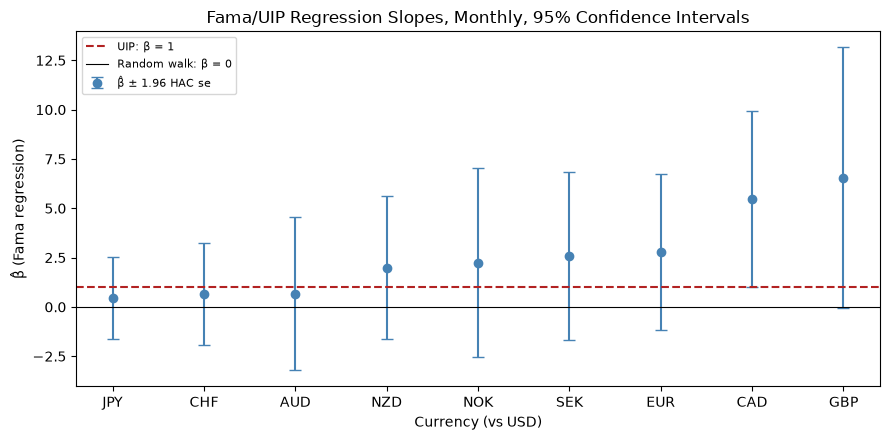

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = fama_df.sort_values("beta_hat").index
x = np.arange(len(order))
ax.errorbar(x, fama_df.loc[order, "beta_hat"], yerr=1.96 * fama_df.loc[order, "beta_se (HAC)"],
            fmt="o", capsize=4, color="steelblue", label="β̂ ± 1.96 HAC se")
ax.axhline(1, color="firebrick", ls="--", label="UIP: β = 1")
ax.axhline(0, color="black", lw=0.8, label="Random walk: β = 0")
ax.set_xticks(x, order)
ax.set_xlabel("Currency (vs USD)")
ax.set_ylabel("β̂ (Fama regression)")
ax.set_title("Fama/UIP Regression Slopes, Monthly, 95% Confidence Intervals")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation (3.3).**

CAD is on the cusp of being rejected, it has a p=0.05. It is in the opposite direction of the puzzle, where the high yielding currencies depreciated more than the rate differential. 

# Section 4 — Building the G10 Carry Basket

## 4.1 — Rank-and-Sort Basket

**Construction.** On the **last trading day of each month** ($t$), rank the nine currencies by their rate differential vs USD. Go long the top 3 and short the bottom 3, equal-weighted within each leg: $+\tfrac13$ each on the long side, $-\tfrac13$ each on the short side. Long notional equals short notional ($1 each), so the basket is dollar-neutral, and its P&L is quoted in **% of $1 of long-leg notional**. A short position in currency $k$ earns $-\text{carry}_k$. Because the legs net to zero against USD, the USD rate cancels out, and the basket earns the differential between the currencies it is long and short.

**No look-ahead, in two places:**
1. **Signal.** The FRED value for month $m$ is an average over month $m$ and is published with a lag. At the end of month $m$ I rank on the **month $m-1$** value (`RANK_LAG_MONTHS = 1`). Months past FRED's last observation reuse the last published value.
2. **Execution.** Weights set at the close of $t$ are held from $t+1$ until the next rebalance. In code this is `W.reindex(days).ffill().shift(1)`. The `shift(1)` is the CS 1 off-by-one fix, applied in one place for every strategy below.

In [22]:
from scipy.stats import t as student_t

N_LONG = N_SHORT = 3
RANK_LAG_MONTHS = 1
days = carry.index

# rebalance/signal dates: last trading day of each month (drop the final day -- nothing left to trade)
rebal_dates = pd.DatetimeIndex(days.to_series().groupby(days.to_period("M")).max().values)
rebal_dates = rebal_dates[rebal_dates < days[-1]]

# monthly rates keyed by period, extended (ffill) past FRED's last obs so recent months have a value
rates_m = rates.copy()
rates_m.index = rates_m.index.to_period("M")
rates_m = rates_m.reindex(pd.period_range(rates_m.index[0], days[-1].to_period("M"), freq="M")).ffill()

rank_diffs = pd.DataFrame(
    {dt: rates_m.loc[dt.to_period("M") - RANK_LAG_MONTHS, NON_USD] - rates_m.loc[dt.to_period("M") - RANK_LAG_MONTHS, "USD"]
     for dt in rebal_dates}).T

def leg_members(dt):
    ranked = rank_diffs.loc[dt].sort_values(ascending=False)
    return list(ranked.index[:N_LONG]), list(ranked.index[-N_SHORT:])

def basket_weights(dates, vol=None):
    """Long top-3 / short bottom-3. Equal weight within leg, or inverse-vol if
    `vol` (a forecast known at each date) is given. Each leg sums to +/-1."""
    W = pd.DataFrame(0.0, index=dates, columns=NON_USD)
    for dt in dates:
        longs, shorts = leg_members(dt)
        for members, sign in ((longs, 1.0), (shorts, -1.0)):
            raw = pd.Series(1.0, index=members) if vol is None else 1.0 / vol.loc[dt, members]
            W.loc[dt, members] = sign * raw / raw.sum()
    return W

n_cal_days = days.to_series().diff().dt.days.fillna(1)

def run_backtest(W, cost_bps=0.0, spread_bps=0.0, returns=carry):
    """Daily P&L for rebalance-date weights W.
    - weights set at close of rebalance date t are held from t+1 (shift(1))
    - transaction cost: cost_bps per unit of turnover, charged on t+1
    - funding spread: every leg earns (long) / pays (short) spread_bps/yr worse
      than the reference rate, accrued over calendar days on gross notional
    All outputs in % of $1 long-leg notional."""
    ix = returns.index
    w_daily = W.reindex(ix).ffill().shift(1).fillna(0.0)
    gross = (w_daily * returns[W.columns]).sum(axis=1)
    turnover = W.diff().abs().sum(axis=1)
    turnover.iloc[0] = W.iloc[0].abs().sum()
    cost = turnover.reindex(ix).shift(1).fillna(0.0) * cost_bps / 100
    drag = w_daily.abs().sum(axis=1) * (spread_bps / 100) * n_cal_days.reindex(ix) / 365
    live = ix > W.index[0]
    return {"gross": gross[live], "net": (gross - cost - drag)[live], "cost": cost[live],
            "drag": drag[live], "turnover": turnover, "w": w_daily[live], "W": W}

def perf_stats(r):
    wealth = np.exp(r.cumsum() / 100)          # returns are log-equivalent %, so compound with exp
    monthly = r.groupby(r.index.to_period("M")).sum()
    return pd.Series({
        "ann. return (%)": 252 * r.mean(),
        "ann. vol (%)": np.sqrt(252) * r.std(),
        "Sharpe": np.sqrt(252) * r.mean() / r.std(),
        "skew (daily)": stats.skew(r),
        "excess kurt (daily)": stats.kurtosis(r),
        "skew (monthly)": stats.skew(monthly),
        "max drawdown (%)": 100 * (wealth / wealth.cummax() - 1).min(),
    })

W_ew = basket_weights(rebal_dates)
bt_ew = run_backtest(W_ew)
print(f"{len(rebal_dates)} monthly rebalances, {rebal_dates[0].date()} to {rebal_dates[-1].date()}")
print("Weights sum to zero every month:", np.allclose(W_ew.sum(axis=1), 0))
perf_stats(bt_ew["gross"]).to_frame("Rank-sort, equal weight (gross)").round(3)

245 monthly rebalances, 2006-05-31 to 2026-09-30
Weights sum to zero every month: True


,"Rank-sort, equal weight (gross)"
ann. return (%),1.780
ann. vol (%),8.744
Sharpe,0.204
skew (daily),-0.631
excess kurt (daily),13.671
skew (monthly),-0.854
max drawdown (%),-32.409


In [23]:
counts = pd.DataFrame({"months long": (W_ew > 0).sum(), "months short": (W_ew < 0).sum(),
                       "months out": (W_ew == 0).sum()})
counts["avg rank diff (%/yr)"] = rank_diffs.mean().round(2)
counts.sort_values("months long", ascending=False)

,months long,months short,months out,avg rank diff (%/yr)
NZD,224,0,21,1.67
AUD,202,0,43,1.34
NOK,144,0,101,0.44
CAD,93,15,137,0.03
GBP,72,15,158,0.05
EUR,0,165,80,-0.78
JPY,0,156,89,-1.64
CHF,0,245,0,-1.62
SEK,0,139,106,-0.66


## 4.2 — Volatility-Targeted (Risk-Parity) Basket

Same monthly membership, but **within each leg** each currency is weighted by $1/\hat\sigma_{k,t+1|t}$ and the leg is renormalized to $\pm 1$. A currency twice as volatile gets half the notional, so the members of a leg contribute roughly equal risk, and the basket stays dollar-neutral.

**Timing, re-derived for nine series.** `arch`'s `conditional_volatility` at date $t$ is $\sigma_{t\mid t-1}$, built from information through $t-1$. The forecast for the next day, which we need at the close of $t$ to size the position held on $t+1$, is

$$\hat\sigma^2_{t+1\mid t} = \hat\omega + \hat\alpha_1(r_t - \hat\mu)^2 + \hat\beta_1\,\hat\sigma^2_{t\mid t-1}.$$

This uses day $t$'s realized return, which is known at the close of $t$, and nothing later. `one_step_sigma` computes it for every currency and every day, so `sigma_fs.loc[t]` is exactly what a trader would know at the close of $t$.

**Caveat:** this section uses the **full-sample** GARCH parameters from 3.2, so the *parameters* still see the future, even though each daily forecast doesn't. Section 5.1 removes that by refitting walk-forward.

In [24]:
def one_step_sigma(res, y):
    """sigma_{t+1|t} for every t, from a fitted (or fixed-parameter) arch result."""
    p = res.params
    eps = y - p["mu"]
    return np.sqrt(p["omega"] + p["alpha[1]"] * eps ** 2 + p["beta[1]"] * res.conditional_volatility ** 2)

sigma_fs = pd.DataFrame({c: one_step_sigma(garch_fits[c]["best"], carry[c]) for c in NON_USD})

W_vt = basket_weights(rebal_dates, vol=sigma_fs)
bt_vt = run_backtest(W_vt)
print("Each leg sums to +/-1:",
      np.allclose(W_vt.clip(lower=0).sum(axis=1), 1), np.allclose(W_vt.clip(upper=0).sum(axis=1), -1))
pd.DataFrame({"Equal weight (gross)": perf_stats(bt_ew["gross"]),
              "Vol-targeted (gross)": perf_stats(bt_vt["gross"])}).round(3)

Each leg sums to +/-1: True True


,Equal weight (gross),Vol-targeted (gross)
ann. return (%),1.780,1.440
ann. vol (%),8.744,8.570
Sharpe,0.204,0.168
skew (daily),-0.631,-0.689
excess kurt (daily),13.671,10.519
skew (monthly),-0.854,-0.623
max drawdown (%),-32.409,-34.027


## 4.3 — Adding Realism: Costs and Funding Spread

* **Transaction cost:** `cost_bps` per unit of notional traded at each rebalance, where turnover $= \sum_k |w_{k,t} - w_{k,t-1}|$, at most 4 per month. G10 spot/forward bid-ask is roughly 1–3 bps for majors and wider for SEK/NOK. Simplification: turnover is target-to-target and ignores intra-month drift in notional.
* **Funding spread:** each leg transacts `spread_bps` per year worse than the reference rate (the long leg earns $i - s$, the short leg pays $i + s$), accrued over calendar days on gross notional (2 for this basket).

Grid: costs {0, 3, 10} bps × spreads {0, 10, 50} bps/yr. **Baseline for the rest of the notebook: 3 bps cost, 10 bps/yr spread.**

In [25]:
COST_GRID, SPREAD_GRID = [0, 3, 10], [0, 10, 50]
COST_BPS, SPREAD_BPS = 3, 10

sens_rows = []
for c in COST_GRID:
    for s in SPREAD_GRID:
        row = {"cost (bps)": c, "spread (bps/yr)": s}
        for name, W in (("EW", W_ew), ("VT", W_vt)):
            r = run_backtest(W, c, s)["net"]
            row[f"{name} ann. ret (%)"] = 252 * r.mean()
            row[f"{name} Sharpe"] = np.sqrt(252) * r.mean() / r.std()
        sens_rows.append(row)
sens_df = pd.DataFrame(sens_rows).set_index(["cost (bps)", "spread (bps/yr)"])

bt_ew_net = run_backtest(W_ew, COST_BPS, SPREAD_BPS)
bt_vt_net = run_backtest(W_vt, COST_BPS, SPREAD_BPS)
yrs = len(bt_ew_net["net"]) / 252
for name, bt in (("EW", bt_ew_net), ("VT", bt_vt_net)):
    print(f"{name}: avg turnover/rebalance {bt['turnover'].iloc[1:].mean():.2f}, "
          f"cost drag {252*bt['cost'].mean():.3f}%/yr, funding drag {252*bt['drag'].mean():.3f}%/yr")
sens_df.round(3)

EW: avg turnover/rebalance 0.11, cost drag 0.042%/yr, funding drag 0.194%/yr
VT: avg turnover/rebalance 0.26, cost drag 0.093%/yr, funding drag 0.194%/yr


EW ann. ret (%)  EW Sharpe  VT ann. ret (%)  \
cost (bps) spread (bps/yr)                                                
0          0                          1.780      0.204            1.440   
           10                         1.586      0.181            1.246   
           50                         0.811      0.093            0.470   
3          0                          1.738      0.199            1.347   
           10                         1.544      0.177            1.153   
           50                         0.769      0.088            0.378   
10         0                          1.640      0.188            1.130   
           10                         1.447      0.165            0.937   
           50                         0.671      0.077            0.161   

                            VT Sharpe  
cost (bps) spread (bps/yr)             
0          0                    0.168  
           10                   0.145  
           50                   0.055  
3          0                    0.157  
           10                   0.135  
           50                   0.044  
10         0                    0.132  
           10                   0.109  
           50                   0.019

**Interpretation (4.3).**

Most of the gross P&L survives the realistic friction, but the edge is thin. Equal weight: 1.78%/yr gross (Sharpe 0.20) falls to 1.54%/yr (0.18) at the baseline 3 bps cost and 10 bps/yr spread, keeping about 87%. At the harshest corner (10 bps, 50 bps/yr) it falls to 0.67%/yr (0.08), keeping about 38%. Vol-targeted: 1.44%/yr (0.17) falls to 1.15%/yr (0.14) at baseline, about 80%, and to 0.16%/yr (0.02) at the harshest corner, about 11%.

The funding spread matters far more than transaction costs. The basket trades very little: average turnover is 0.11 (EW) or 0.26 (VT) units of notional per month out of a possible 4, because membership is sticky (NZD and AUD are long most months, CHF is short every single month). So 3 bps of cost costs only 0.04–0.09%/yr. The funding spread, by contrast, is paid every day on the full gross notional of 2: 0.19%/yr at 10 bps and about 1%/yr at 50 bps.

Vol-targeting raises turnover about 2.4×: weights shift every month as relative volatilities change, even when membership doesn't. It therefore pays more in transaction costs, though that is still small next to funding.

## 4.4 — Basket vs. Single Pair

Over the **same dates** (from the first rebalance), and with the **same frictions** applied to all three: (a) AUD/JPY as a constant long-AUD/short-JPY position ($1 each side, the same footing as the basket), (b) the equal-weight rank-and-sort basket, and (c) the vol-targeted basket. I report both gross and net.

In [26]:
W_audjpy = pd.DataFrame(0.0, index=rebal_dates, columns=NON_USD)
W_audjpy["AUD"], W_audjpy["JPY"] = 1.0, -1.0

strategies_44 = {"AUD/JPY single pair": W_audjpy, "Rank-sort EW basket": W_ew, "Vol-targeted basket": W_vt}
comp_rows = {}
for name, W in strategies_44.items():
    bt = run_backtest(W, COST_BPS, SPREAD_BPS)
    comp_rows[(name, "gross")] = perf_stats(bt["gross"])
    comp_rows[(name, "net")] = perf_stats(bt["net"])
comp_44 = pd.DataFrame(comp_rows).T
comp_44.index.names = ["strategy", ""]
comp_44.round(3)

ann. return (%)  ann. vol (%)  Sharpe  \
strategy                                                           
AUD/JPY single pair gross            4.028        15.507   0.260   
                    net              3.831        15.507   0.247   
Rank-sort EW basket gross            1.780         8.744   0.204   
                    net              1.544         8.745   0.177   
Vol-targeted basket gross            1.440         8.570   0.168   
                    net              1.153         8.570   0.135   

                           skew (daily)  excess kurt (daily)  skew (monthly)  \
strategy                                                                       
AUD/JPY single pair gross        -0.612               19.560          -1.199   
                    net          -0.612               19.560          -1.199   
Rank-sort EW basket gross        -0.631               13.671          -0.854   
                    net          -0.631               13.669          -0.855   
Vol-targeted basket gross        -0.689               10.519          -0.623   
                    net          -0.689               10.521          -0.626   

                           max drawdown (%)  
strategy                                     
AUD/JPY single pair gross           -44.972  
                    net             -45.001  
Rank-sort EW basket gross           -32.409  
                    net             -32.669  
Vol-targeted basket gross           -34.027  
                    net             -34.386

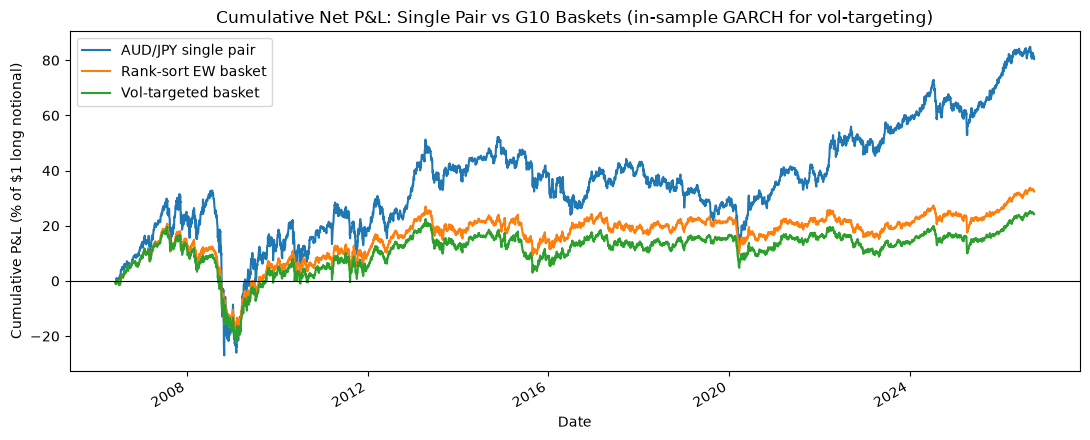

Average pairwise correlation of the nine carry series: 0.49


In [27]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for name, W in strategies_44.items():
    run_backtest(W, COST_BPS, SPREAD_BPS)["net"].cumsum().plot(ax=ax, label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Cumulative Net P&L: Single Pair vs G10 Baskets (in-sample GARCH for vol-targeting)")
ax.set_ylabel("Cumulative P&L (% of $1 long notional)")
ax.set_xlabel("Date")
ax.legend()
plt.tight_layout()
plt.show()

avg_corr = carry.corr().where(~np.eye(9, dtype=bool)).stack().mean()
print(f"Average pairwise correlation of the nine carry series: {avg_corr:.2f}")

**Interpretation (4.4).**

The basket does not beat the single pair over the same dates. AUD/JPY 0.26 gross / 0.25 net, versus 0.20 / 0.18 (equal weight) and 0.17 / 0.14 (vol-targeted). The basket's advantage is lower risk in absolute terms. Volatility is about 8.6% vs 15.5%, and max drawdown −32% to −34% vs −45%.

# Section 5 — Full Backtest and Risk Tearsheet

## 5.1 — Walk-Forward Loop

At every monthly rebalance $t$, using only data through $t$:
* **(a) Rank** on the lagged rate differential. This is already walk-forward by construction (4.1).
* **(b) Volatility:** GARCH(1,1)-$t$ parameters are **refit every 12 months** on an expanding window ending at the refit date. Between refits the parameters stay fixed, but the variance forecast $\hat\sigma_{t+1|t}$ still **updates daily** through the GARCH recursion as each day's return comes in.
* **(c) Weight** each leg by inverse forecast vol, then trade from $t+1$ with the baseline costs and funding spread (4.3).

**Why annual refits.** 3.2 found persistence of 0.99 or more for every currency, and the parameters of a slow-moving variance process don't change much month to month. That's the lecture's point that GARCH parameters can be trusted longer than an ARMA fit. What matters for sizing is the *state*, today's $\hat\sigma$, and that is updated every day. Refitting monthly would cost 12× the compute for little gain. Each refit needs at least 500 trading days (about 2 years), so the walk-forward backtest starts in **2008**, which leaves the 2008 crash in the out-of-sample period with a model trained only on the calm 2006–08 data.

Between refits, `arch_model(...).fix(params)` runs the recursion with frozen parameters. It uses only data up to the end of each segment, and its starting variance comes from the start of the sample, not the end.

In [28]:
MIN_TRAIN_OBS = 500
REFIT_EVERY = 12            # rebalances (months)

wf_rebal = rebal_dates[rebal_dates >= days[MIN_TRAIN_OBS]]
refit_dates = wf_rebal[::REFIT_EVERY]

def walk_forward_sigma(y, refit_dates):
    """sigma_{t+1|t} with parameters estimated only on data through the latest refit <= t."""
    sig = pd.Series(np.nan, index=y.index)
    nu = pd.Series(np.nan, index=y.index)
    log = []
    for k, rd in enumerate(refit_dates):
        end = refit_dates[k + 1] if k + 1 < len(refit_dates) else y.index[-1]
        fit = arch_model(y.loc[:rd], mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
        seg = y.loc[:end]
        fixed = arch_model(seg, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fix(fit.params)
        sig.loc[rd:end] = one_step_sigma(fixed, seg).loc[rd:end]
        nu.loc[rd:end] = fit.params["nu"]
        log.append({"refit date": rd.date(), **fit.params.round(4).to_dict()})
    return sig, nu, pd.DataFrame(log)

sigma_wf, nu_wf, wf_params = {}, {}, {}
for ccy in NON_USD:
    sigma_wf[ccy], nu_wf[ccy], wf_params[ccy] = walk_forward_sigma(carry[ccy], refit_dates)
sigma_wf, nu_wf = pd.DataFrame(sigma_wf), pd.DataFrame(nu_wf)

print(f"{len(refit_dates)} annual refits per currency, {refit_dates[0].date()} to {refit_dates[-1].date()}")
print(f"Walk-forward trading from {wf_rebal[0].date()} ({len(wf_rebal)} rebalances)")
wf_params["AUD"]

19 annual refits per currency, 2008-04-30 to 2026-04-30
Walk-forward trading from 2008-04-30 (222 rebalances)


,refit date,mu,omega,alpha[1],beta[1],nu
0,2008-04-30,0.0652,0.0021,0.0410,0.9559,6.7745
1,2009-04-30,0.0530,0.0066,0.0956,0.9035,6.6951
2,2010-04-30,0.0586,0.0057,0.0795,0.9167,8.0408
3,2011-04-29,0.0699,0.0071,0.0806,0.9137,8.1877
4,2012-04-30,0.0622,0.0082,0.0828,0.9099,9.0019
5,2013-04-30,0.0475,0.0051,0.0746,0.9205,9.0751
6,2014-04-30,0.0392,0.0054,0.0731,0.9207,9.8067
7,2015-04-30,0.0280,0.0050,0.0724,0.9219,10.0403
8,2016-04-29,0.0244,0.0047,0.0671,0.9275,10.8758
9,2017-04-28,0.0221,0.0045,0.0628,0.9310,10.8321


In [29]:
W_wf_vt = basket_weights(wf_rebal, vol=sigma_wf)
W_wf_ew = basket_weights(wf_rebal)

bt_wf = run_backtest(W_wf_vt, COST_BPS, SPREAD_BPS)          # the strategy
bt_wf_ew = run_backtest(W_wf_ew, COST_BPS, SPREAD_BPS)       # same window, equal weight, for 5.3
wf_days = bt_wf["net"].index

pd.DataFrame({
    "VT walk-forward (gross)": perf_stats(bt_wf["gross"]),
    "VT walk-forward (net)": perf_stats(bt_wf["net"]),
    "VT in-sample GARCH (net, same dates)": perf_stats(bt_vt_net["net"].loc[wf_days]),
    "EW (net, same dates)": perf_stats(bt_wf_ew["net"]),
}).round(3)

,VT walk-forward (gross),VT walk-forward (net),"VT in-sample GARCH (net, same dates)","EW (net, same dates)"
ann. return (%),1.020,0.731,0.870,1.142
ann. vol (%),8.470,8.471,8.508,8.607
Sharpe,0.120,0.086,0.102,0.133
skew (daily),-0.735,-0.736,-0.710,-0.644
excess kurt (daily),11.343,11.347,11.555,15.577
skew (monthly),-0.651,-0.655,-0.670,-0.929
max drawdown (%),-27.951,-28.101,-27.439,-26.891


## 5.2 — Performance Report: The Tearsheet

**95% conditional VaR from the GARCH-$t$ fits.** At the close of $t$, for the weights $w$ that will be held on $t+1$:

$$\Sigma_{t+1|t} = D_t R_t D_t,\qquad D_t = \operatorname{diag}(\hat\sigma_{k,t+1|t}^{\text{walk-fwd}}),\qquad \hat\sigma_{p} = \sqrt{w^\top \Sigma_{t+1|t}\, w}$$

$$\text{VaR}_{95,t+1} = -\hat\sigma_p\; q_{0.05}(\nu_t)\sqrt{\tfrac{\nu_t-2}{\nu_t}}$$

* $R_t$ is the **trailing 126-day** correlation of the carry series through $t$, not a full-sample matrix (which would be look-ahead). A full DCC model is out of scope.
* $\nu_t$ is the median of the nine currencies' walk-forward $\hat\nu$. The $\sqrt{(\nu-2)/\nu}$ factor is needed because `arch`'s Student-$t$ is standardized to unit variance, while `scipy`'s quantile is for the unscaled $t$. Leaving it out overstates VaR.
* **Backtest:** a 95% VaR should be exceeded on about 5% of days.

**Capital convention:** "% of initial capital" means % of the $1 long-leg notional, the same unit as every P&L number here.

In [30]:
CORR_WINDOW = 126
VAR_LEVEL = 0.05

roll_corr = carry.rolling(CORR_WINDOW).corr().to_numpy().reshape(len(days), 9, 9)
pos = {d: i for i, d in enumerate(days)}
w_next = W_wf_vt.reindex(days).ffill().fillna(0.0)          # at close of t: weights to be held on t+1

port_sigma = pd.Series(np.nan, index=days)
for t in sigma_wf.dropna().index:
    w = w_next.loc[t].to_numpy()
    s = sigma_wf.loc[t].to_numpy()
    R = roll_corr[pos[t]]
    if np.isnan(R).any():
        continue
    port_sigma.loc[t] = np.sqrt(w @ (np.outer(s, s) * R) @ w)

nu_t = nu_wf.median(axis=1)
q_std = student_t.ppf(VAR_LEVEL, nu_t) * np.sqrt((nu_t - 2) / nu_t)
VaR95 = (-port_sigma * q_std).shift(1).reindex(wf_days)          # forecast made at t, labelled on t+1
realized_loss = -bt_wf["net"]
exceed = realized_loss > VaR95
print(f"VaR exceedances: {exceed.sum()} of {VaR95.notna().sum()} days "
      f"= {100*exceed.mean():.2f}% (target {100*VAR_LEVEL:.0f}%)")

r = bt_wf["net"]
yrs = len(r) / 252
tearsheet = pd.Series({
    "Sample": f"{r.index[0].date()} to {r.index[-1].date()}",
    "Annualized return (%)": 252 * r.mean(),
    "Annualized volatility (%)": np.sqrt(252) * r.std(),
    "Sharpe ratio": np.sqrt(252) * r.mean() / r.std(),
    "Skewness (daily)": stats.skew(r),
    "Skewness (monthly)": stats.skew(r.groupby(r.index.to_period("M")).sum()),
    "Excess kurtosis (daily)": stats.kurtosis(r),
    "Maximum drawdown (%)": perf_stats(r)["max drawdown (%)"],
    "Worst day (%)": r.min(),
    "Worst month (%)": r.groupby(r.index.to_period("M")).sum().min(),
    "95% conditional VaR, average (%/day)": VaR95.mean(),
    "95% conditional VaR, latest (%/day)": VaR95.dropna().iloc[-1],
    "VaR exceedance rate (%)": 100 * exceed.mean(),
    "Total turnover (annualized, notional/yr)": bt_wf["turnover"].sum() / yrs,
    "Transaction costs paid (% of capital)": bt_wf["cost"].sum(),
    "Funding spread paid (% of capital)": bt_wf["drag"].sum(),
    "Total costs + funding spread (% of capital)": bt_wf["cost"].sum() + bt_wf["drag"].sum(),
}, dtype=object)
tearsheet.apply(lambda v: round(v, 3) if isinstance(v, float) else v).to_frame("Walk-forward vol-targeted basket (net)")

VaR exceedances: 242 of 4796 days = 5.05% (target 5%)


,Walk-forward vol-targeted basket (net)
Sample,2008-05-02 to 2026-10-02
Annualized return (%),0.731
Annualized volatility (%),8.471
Sharpe ratio,0.086
Skewness (daily),-0.736
Skewness (monthly),-0.655
Excess kurtosis (daily),11.347
Maximum drawdown (%),-28.101
Worst day (%),-4.789
Worst month (%),-9.316


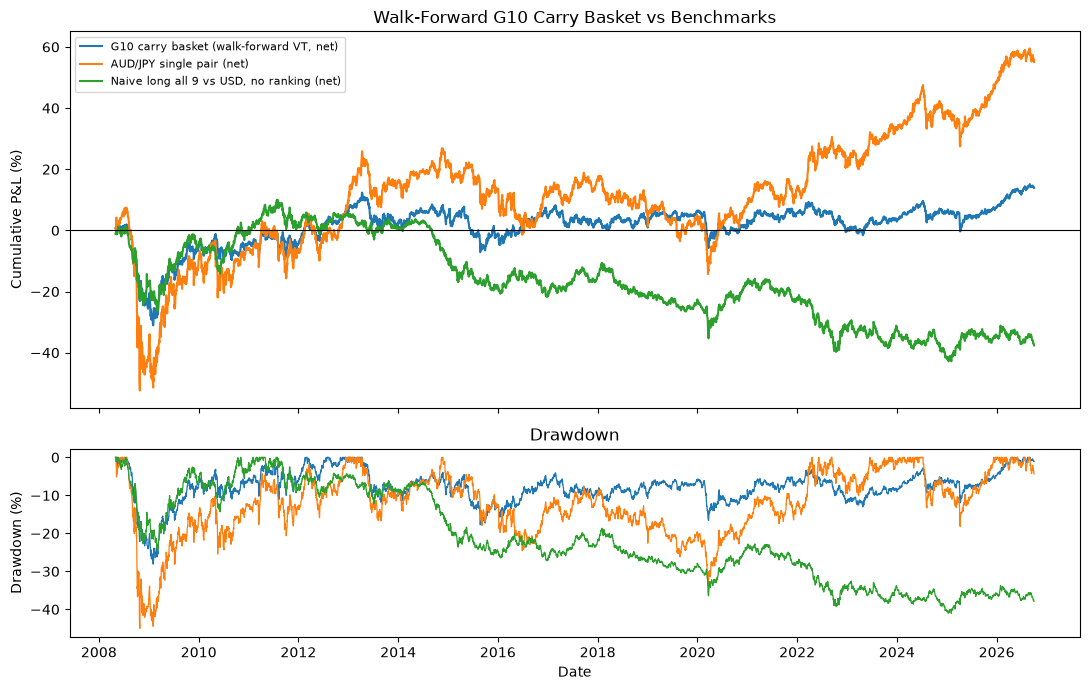

,"G10 carry basket (walk-forward VT, net)",AUD/JPY single pair (net),"Naive long all 9 vs USD, no ranking (net)"
ann. return (%),0.731,2.894,-1.977
ann. vol (%),8.471,15.407,8.021
Sharpe,0.086,0.188,-0.246
skew (daily),-0.736,-0.581,0.057
excess kurt (daily),11.347,21.626,2.579
skew (monthly),-0.655,-1.295,-0.138
max drawdown (%),-28.101,-45.001,-41.046


In [31]:
W_naive = pd.DataFrame(1.0 / 9, index=wf_rebal, columns=NON_USD)       # long all nine vs USD, $1 total
W_pair = W_audjpy.loc[wf_rebal]
benchmarks = {
    "G10 carry basket (walk-forward VT, net)": bt_wf["net"],
    "AUD/JPY single pair (net)": run_backtest(W_pair, COST_BPS, SPREAD_BPS)["net"],
    "Naive long all 9 vs USD, no ranking (net)": run_backtest(W_naive, COST_BPS, SPREAD_BPS)["net"],
}

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for name, rr in benchmarks.items():
    axes[0].plot(rr.index, rr.cumsum(), label=name)
    wealth = np.exp(rr.cumsum() / 100)
    axes[1].plot(rr.index, 100 * (wealth / wealth.cummax() - 1), lw=0.9, label=name)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("Walk-Forward G10 Carry Basket vs Benchmarks")
axes[0].set_ylabel("Cumulative P&L (%)")
axes[0].legend(fontsize=8)
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Date")
plt.tight_layout()
plt.show()

pd.DataFrame({k: perf_stats(v) for k, v in benchmarks.items()}).round(3)

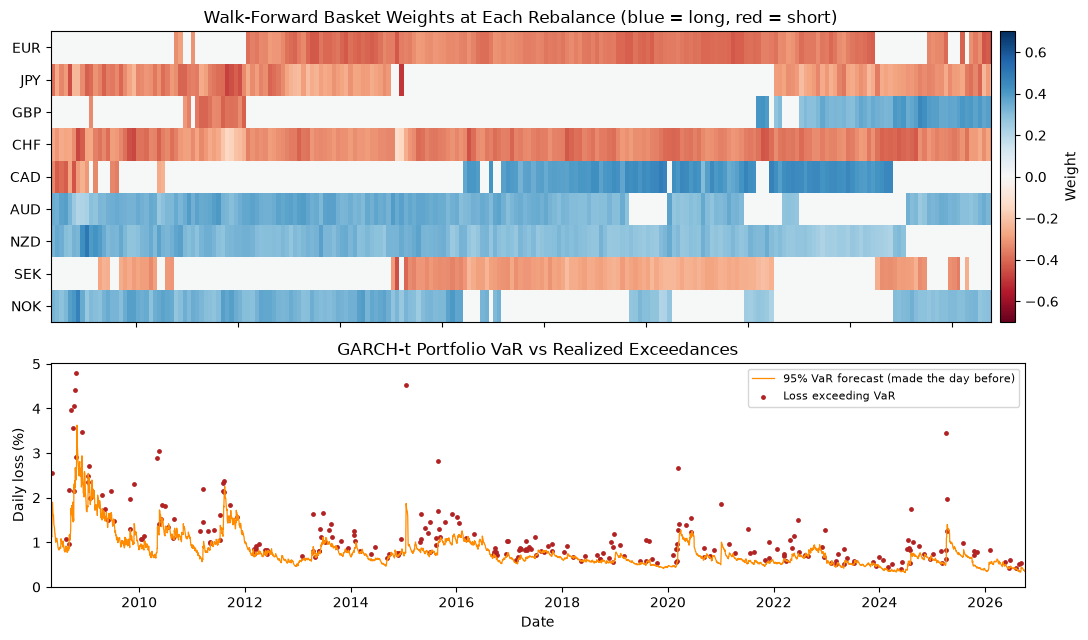

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
Wp = W_wf_vt.T
x_edges = list(W_wf_vt.index) + [days[-1]]       # each column = one holding period
mesh = axes[0].pcolormesh(x_edges, np.arange(len(NON_USD) + 1), Wp.to_numpy(),
                          cmap="RdBu", vmin=-0.7, vmax=0.7, shading="flat")
axes[0].set_yticks(np.arange(len(NON_USD)) + 0.5, NON_USD)
axes[0].invert_yaxis()
axes[0].set_title("Walk-Forward Basket Weights at Each Rebalance (blue = long, red = short)")
fig.colorbar(mesh, ax=axes[0], label="Weight", fraction=0.025, pad=0.01)

axes[1].plot(VaR95.index, VaR95, color="darkorange", lw=0.9, label="95% VaR forecast (made the day before)")
axes[1].scatter(realized_loss.index[exceed], realized_loss[exceed], s=6, color="firebrick", label="Loss exceeding VaR")
axes[1].set_ylim(0, None)
axes[1].set_title("GARCH-t Portfolio VaR vs Realized Exceedances")
axes[1].set_ylabel("Daily loss (%)")
axes[1].set_xlabel("Date")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Crash episodes.** The walk-forward sample includes the 2008 crisis, the 2015 SNB de-peg (CHF is a frequent short-leg member, so a sudden CHF appreciation hurts this basket directly), the March 2020 COVID dash for dollars, and the August 2024 JPY carry unwind. For each window I show the basket's drawdown and whether the VaR forecast (made the evening before) rose **before** the worst losses or only **after**.

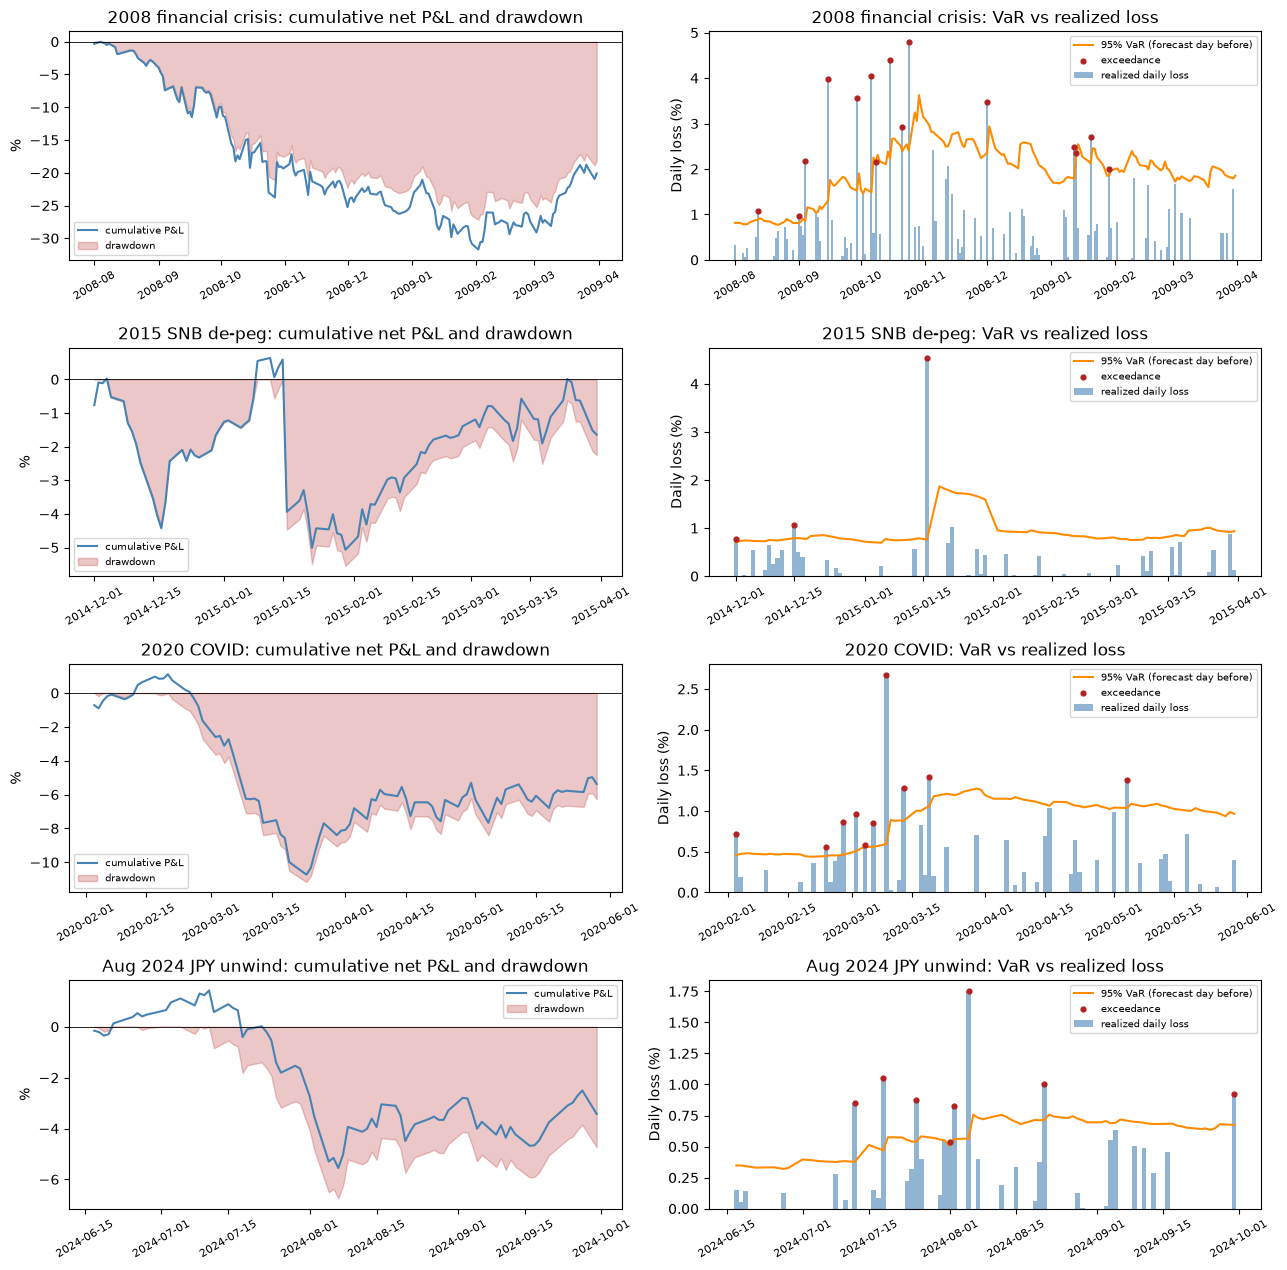

,P&L over window (%),max DD in window (%),worst day,worst-day P&L (%),VaR at window start (%),VaR on worst day (%),peak VaR (%),peak VaR date,exceedances,days
episode,,,,,,,,,,
2008 financial crisis,-20.110,-27.174,2008-10-24,-4.789,0.815,2.405,3.626,2008-10-29,15,173
2015 SNB de-peg,-1.643,-5.543,2015-01-16,-4.528,0.698,0.763,1.869,2015-01-19,3,87
2020 COVID,-5.375,-11.168,2020-03-09,-2.675,0.458,0.595,1.276,2020-03-30,10,85
Aug 2024 JPY unwind,-3.428,-6.743,2024-08-05,-1.753,0.348,0.564,0.757,2024-08-22,8,76


In [33]:
EPISODES = {
    "2008 financial crisis": ("2008-08-01", "2009-03-31"),
    "2015 SNB de-peg": ("2014-12-01", "2015-03-31"),
    "2020 COVID": ("2020-02-01", "2020-05-29"),
    "Aug 2024 JPY unwind": ("2024-06-17", "2024-09-30"),
}

ep_rows = []
fig, axes = plt.subplots(len(EPISODES), 2, figsize=(13, 3.2 * len(EPISODES)))
for row, (label, (a, b)) in enumerate(EPISODES.items()):
    rr = bt_wf["net"].loc[a:b]
    var_w, loss_w, exc_w = VaR95.loc[a:b], realized_loss.loc[a:b], exceed.loc[a:b]
    cum = rr.cumsum()
    dd = 100 * (np.exp(cum / 100) / np.exp(cum / 100).cummax() - 1)
    worst = rr.idxmin()
    ep_rows.append({
        "episode": label, "P&L over window (%)": rr.sum(), "max DD in window (%)": dd.min(),
        "worst day": worst.date(), "worst-day P&L (%)": rr.min(),
        "VaR at window start (%)": var_w.iloc[0], "VaR on worst day (%)": var_w.loc[worst],
        "peak VaR (%)": var_w.max(), "peak VaR date": var_w.idxmax().date(),
        "exceedances": int(exc_w.sum()), "days": len(rr),
    })
    ax = axes[row, 0]
    ax.plot(cum.index, cum, color="steelblue", label="cumulative P&L")
    ax.fill_between(dd.index, dd, 0, color="firebrick", alpha=0.25, label="drawdown")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{label}: cumulative net P&L and drawdown")
    ax.set_ylabel("%")
    ax.legend(fontsize=7)
    ax = axes[row, 1]
    ax.bar(loss_w.index, loss_w.clip(lower=0), width=1.0, color="steelblue", alpha=0.6, label="realized daily loss")
    ax.plot(var_w.index, var_w, color="darkorange", lw=1.5, label="95% VaR (forecast day before)")
    ax.scatter(loss_w.index[exc_w], loss_w[exc_w], color="firebrick", s=12, zorder=3, label="exceedance")
    ax.set_title(f"{label}: VaR vs realized loss")
    ax.set_ylabel("Daily loss (%)")
    ax.legend(fontsize=7)
for ax in axes.flat:
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(ep_rows).set_index("episode").round(3)

In [34]:
# Who was in the basket going into each episode?
pd.DataFrame({label: W_wf_vt.loc[:a].iloc[-1].round(2) for label, (a, b) in EPISODES.items()}).T

,EUR,JPY,GBP,CHF,CAD,AUD,NZD,SEK,NOK
2008 financial crisis,0.00,-0.30,0.00,-0.28,-0.42,0.38,0.30,0.00,0.32
2015 SNB de-peg,-0.36,-0.30,0.00,-0.34,0.00,0.33,0.33,0.00,0.34
2020 COVID,-0.42,0.00,0.00,-0.35,0.45,0.00,0.27,-0.23,0.28
Aug 2024 JPY unwind,-0.42,-0.26,0.35,-0.32,0.40,0.00,0.25,0.00,0.00


### PM-Facing Recommendation

Over 2008–2026, the vol-targeted G10 carry basket returned 0.7%/yr at 8.5% volatility (Sharpe 0.09). It came with negative skew (−0.74 daily, −0.66 monthly), excess kurtosis of 11, and a −28% max drawdown that took years to recover. The GARCH-$t$ VaR is well calibrated on average (5.05% exceedances against a 5% target), but in every crash episode it rose after the worst day, so it would not have protected the book in time. I would not recommend a standalone allocation. At most, the strategy merits a small, tightly risk-budgeted sleeve, conditional on a basket-level volatility target or drawdown stop, a cap on the perennial short-CHF/JPY funding exposure, and re-evaluation once rate dispersion across the G10 is wide enough to make the carry signal meaningful again.

## 5.3 — Interpretation

The table below collects the comparisons the four questions need, all over the walk-forward window.

In [35]:
wf_ew_gross = run_backtest(W_wf_ew)["gross"]
wf_vt_gross = bt_wf["gross"]

def tail_stats(r):
    s = perf_stats(r)
    s["worst day (%)"] = r.min()
    s["avg of worst 1% days (%)"] = r[r <= r.quantile(0.01)].mean()
    s["worst month (%)"] = r.groupby(r.index.to_period("M")).sum().min()
    return s

evidence = pd.DataFrame({
    "EW frictionless": tail_stats(wf_ew_gross),
    "EW net": tail_stats(bt_wf_ew["net"]),
    "VT frictionless": tail_stats(wf_vt_gross),
    "VT net": tail_stats(bt_wf["net"]),
}).round(3)
evidence

,EW frictionless,EW net,VT frictionless,VT net
ann. return (%),1.379,1.142,1.020,0.731
ann. vol (%),8.607,8.607,8.470,8.471
Sharpe,0.160,0.133,0.120,0.086
skew (daily),-0.644,-0.644,-0.735,-0.736
excess kurt (daily),15.577,15.577,11.343,11.347
skew (monthly),-0.928,-0.929,-0.651,-0.655
max drawdown (%),-26.798,-26.891,-27.951,-28.101
worst day (%),-5.763,-5.763,-4.789,-4.789
avg of worst 1% days (%),-2.448,-2.450,-2.430,-2.432
worst month (%),-11.569,-11.586,-9.282,-9.316


**Vol-targeting vs equal weight:** Over the walk-forward window, vol-targeting trimmed the single worst day (−4.8% vs −5.8%), the worst month (−9.3% vs −11.6%) and daily kurtosis (11.3 vs 15.6). It made monthly skew less negative (−0.65 vs −0.93). But it did not reduce max drawdown (−28.1% vs −26.9%) or the average of the worst 1% of days (−2.43% vs −2.45%), and it cost return (Sharpe 0.09 vs 0.13 net). The mechanism explains why: inverse-vol weighting only reallocates *within* each leg, and each leg still sums to ±1. When every currency's volatility rises together, as in 2008, total exposure doesn't fall at all. On top of that, the GARCH forecast lags the shock.

**Frictions shrink a weak result but don't change the verdict.** Frictionless Sharpe was 0.16 (EW) and 0.12 (VT); net it is 0.13 and 0.09. Total frictions came to 5.5% of capital over 18 years (1.8% transaction costs, 3.7% funding spread), about 0.3%/yr against a gross edge of about 1%/yr. The strategy was marginal before costs and is marginal after.

**"A small premium in exchange for rare, large losses."** The average return is 0.73%/yr, or about 0.003%/day. The single worst day (−4.8%, 2008-10-24) wiped out about 6.5 years of average daily gains, and the 2008 episode (−20% P&L, −27% drawdown) wiped out about 27 years of average annual return. Skew is negative at both daily and monthly horizons, kurtosis is 11, and the crash table shows sharp losses in four separate episodes: 2008 (−27% drawdown), COVID 2020 (−11%), August 2024 (−6.7%) and the SNB de-peg (−4.5% in one day). That is the "nickels in front of a steamroller" profile, not a steady edge.

**First change: a basket-level risk control that reacts faster than GARCH.** The episode zoom-ins show VaR rising after the damage. In 2008 it was 0.8% going in, 2.4% on the worst day, and peaked at 3.6% five days later. On the SNB day it was 0.76% against a 4.5% loss. I'd scale total gross exposure to a portfolio volatility target driven by a short realized-vol window, or simply by the drawdown itself. Section 6 suggests a slow trend filter also cuts crash drawdowns sharply (2008: −27% to −5% with a 12-month filter). A close second: cap the CHF short, which was held in all 245 months and turned a single SNB announcement into a −4.5% day.

# Section 6 — Bonus: A Trend Overlay to Manage Crash Risk

**Signal.** At each rebalance $t$, currency $k$ is in an uptrend if its spot (USD per unit) is above its trailing moving average through $t$, and in a downtrend if below. A rising series means the foreign currency is strengthening, so "uptrend" agrees with a long carry position.

**Rule.** Keep a leg member only if its trend agrees with its carry direction. Two ways to handle the members that are dropped:
* **Flat:** zero the member and leave the rest of the leg as it was (the prompt's "go flat"). The legs no longer match in notional, so the book picks up **net USD exposure**. That was the flaw in the reference version.
* **Renormalized** (my preferred choice): zero the member and rescale the survivors in that leg, keeping their inverse-vol ratios, so each leg still sums to ±1 and the book stays dollar-neutral. If *every* member of a leg is dropped, the whole book goes flat for the month, since a one-sided book would be a pure USD bet.

**USD-quoted vs relative trend.** Every spot series is quoted against USD, so a currency's own trend is mostly the *dollar's* trend: when USD rallies broadly, all nine currencies sit below their moving averages at once. In a dollar-neutral book, that empties the entire long leg in a USD rally, or the entire short leg in a USD sell-off. So I also test a relative trend, which takes out the common dollar move:

$$x_{k,t} = \ln S_{k,t} - \tfrac19\textstyle\sum_j \ln S_{j,t},\qquad \text{uptrend if } x_{k,t} > \text{its trailing moving average}.$$


Variants: 3-month (63-day) and 12-month (252-day) windows, USD-quoted and relative, on top of the 5.1 walk-forward basket with the same baseline frictions.

In [36]:
fx_d = fx.reindex(days)

log_fx_d = np.log(fx_d)
rel_fx_d = log_fx_d.sub(log_fx_d.mean(axis=1), axis=0)      # dollar factor removed

def trend_sign(window, relative=False):
    x = rel_fx_d if relative else log_fx_d
    return np.sign(x - x.rolling(window).mean())

def overlay(W, trend, mode):
    W2 = W.copy()
    for dt in W.index:
        w, tr = W.loc[dt], trend.loc[dt]
        keep = w.where((np.sign(w) == tr) | (w == 0), 0.0)
        if mode == "flat":
            W2.loc[dt] = keep
            continue
        L, S = keep[keep > 0], keep[keep < 0]
        if L.empty or S.empty:
            W2.loc[dt] = 0.0
        else:
            W2.loc[dt] = pd.concat([L / L.sum(), S / -S.sum()]).reindex(w.index, fill_value=0.0)
    return W2

overlay_variants = {
    "No overlay (5.1 basket)": W_wf_vt,
    "3m trend, flat": overlay(W_wf_vt, trend_sign(63), "flat"),
    "3m trend, renormalized": overlay(W_wf_vt, trend_sign(63), "renorm"),
    "12m trend, renormalized": overlay(W_wf_vt, trend_sign(252), "renorm"),
    "3m relative trend, renormalized": overlay(W_wf_vt, trend_sign(63, relative=True), "renorm"),
    "12m relative trend, renormalized": overlay(W_wf_vt, trend_sign(252, relative=True), "renorm"),
}

ov_rows, ov_net = {}, {}
for name, W in overlay_variants.items():
    bt = run_backtest(W, COST_BPS, SPREAD_BPS)
    ov_net[name] = bt["net"]
    s = perf_stats(bt["net"])
    s["avg |net USD exposure|"] = W.sum(axis=1).abs().mean()
    s["months fully flat (%)"] = 100 * (W.abs().sum(axis=1) == 0).mean()
    s["ann. turnover"] = bt["turnover"].sum() / (len(bt["net"]) / 252)
    for label, (a, b) in EPISODES.items():
        cum = bt["net"].loc[a:b].cumsum()
        s[f"DD: {label} (%)"] = 100 * (np.exp(cum / 100) / np.exp(cum / 100).cummax() - 1).min()
    ov_rows[name] = s
pd.DataFrame(ov_rows).round(3)

,No overlay (5.1 basket),"3m trend, flat","3m trend, renormalized","12m trend, renormalized","3m relative trend, renormalized","12m relative trend, renormalized"
ann. return (%),0.731,-0.552,-0.657,0.623,-0.562,0.428
ann. vol (%),8.471,7.935,6.511,5.090,8.556,7.957
Sharpe,0.086,-0.070,-0.101,0.122,-0.066,0.054
skew (daily),-0.736,-0.694,2.054,-0.327,-0.282,-0.413
excess kurt (daily),11.347,6.880,75.098,12.348,5.781,5.603
skew (monthly),-0.655,-0.143,-1.117,1.070,-0.096,-0.068
max drawdown (%),-28.101,-30.490,-27.681,-14.574,-35.905,-24.720
avg |net USD exposure|,0.000,0.686,0.000,0.000,0.000,0.000
months fully flat (%),0.000,1.802,65.315,62.613,22.523,23.423
ann. turnover,3.184,9.243,11.721,8.402,18.494,11.199


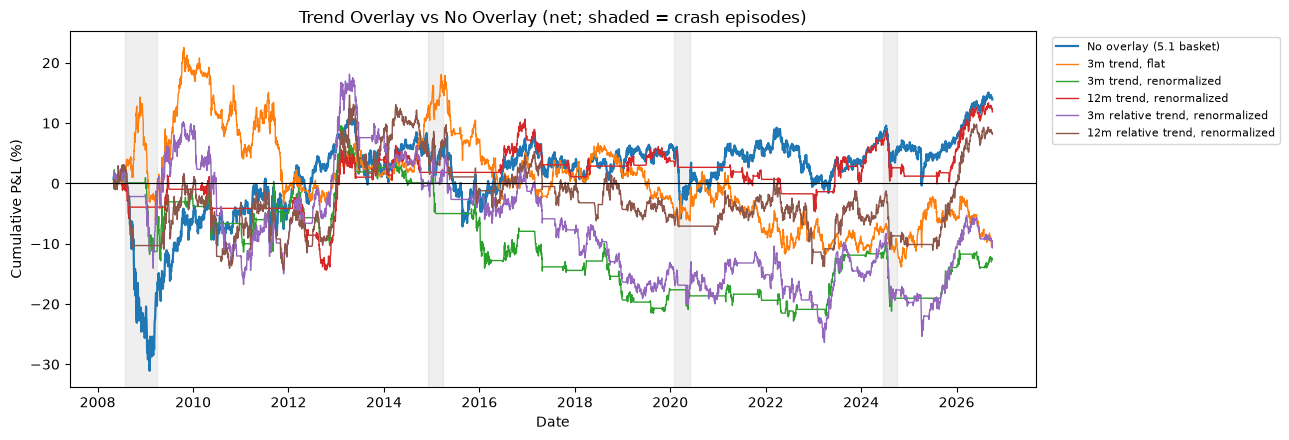

In [37]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, rr in ov_net.items():
    ax.plot(rr.index, rr.cumsum(), label=name, lw=1.6 if name.startswith("No") else 1.0)
for label, (a, b) in EPISODES.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="gray", alpha=0.12)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Trend Overlay vs No Overlay (net; shaded = crash episodes)")
ax.set_ylabel("Cumulative P&L (%)")
ax.set_xlabel("Date")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


**6.** Every overlay cut the 2008 drawdown sharply, from −27% to between −5% (12-month USD-quoted) and −18% (3-month flat). Only the 12-month versions avoided losing money overall, though, and only one beat the unfiltered Sharpe.

* **3-month windows hurt.** All three 3-month variants turned a 0.7%/yr return into a loss of about −0.6%/yr. They whipsaw: turnover rises from 3 to 9–18 units/yr, and the filter flips in and out around short reversals. The 3-month relative version had the *worst* max drawdown of all (−36%).
* **12-month USD-quoted, renormalized** has the best Sharpe (0.12 vs 0.09) and halves max drawdown (−14.6% vs −28.1%), with lower volatility (5.1% vs 8.5%) and *positive* monthly skew (+1.07). But it is completely flat in **63% of months**, so most of its improvement comes from being out of the market.
* **Flat vs renormalized:** "flat" leaves the book with an average net USD exposure of 0.69, nearly a full unit of directional dollar risk. It is no longer a carry book. Renormalizing keeps it dollar-neutral.

**Speed.** The overlays help most in *slow* unwinds (2008 built over months). None helped much in the *sudden* August 2024 unwind, where drawdowns of −8% to −11% were as bad as or worse than no overlay (−6.7%): a 63- or 252-day moving average can't react to a move that happens within a week. Renormalizing concentrates the book in fewer surviving currencies, which made the 3-month variants worse there.

